# VLR.gg — VCT 2026 EMEA Stage 2 : Scraping + Analyse Roster

**Objectif de l'analyse** : identifier, pour chaque équipe, des **désajustements statistiques
rôle/performance** pouvant justifier un mouvement de roster (joueur qui porte une équipe faible,
joueur en retrait dans une équipe forte, lacune ou redondance de rôle dans une composition).

⚠️ **Ce que ce notebook ne fait PAS** : prédire quel joueur va réellement être transféré. Les
transferts VCT dépendent de contrats, de budgets d'organisation, de fit humain/coaching, de
visibilité media — aucune de ces variables n'est dans ce dataset. Ce notebook produit des
**hypothèses statistiquement défendables**, pas des prédictions.

## Structure du notebook

**Partie 1 — Scraping & nettoyage**
1. Récupération de la page de stats
2. Parsing du tableau (joueur, équipe, nationalité, agents, stats)
3. Nettoyage et typage
4. Tests de cohérence

**Partie 2 — Enrichissement & analyse**
5. Mapping rôles (Duelist / Initiator / Controller / Sentinel)
6. Scraping des résultats de matchs → indicateur de force d'équipe
7. Feature engineering (z-scores par rôle, écart joueur/coéquipiers, redondance de rôle)
8. Visualisations
9. Synthèse par équipe
10. Export Excel enrichi
11. Limites méthodologiques

**Prérequis :**
```
pip install requests beautifulsoup4 pandas openpyxl lxml pycountry matplotlib seaborn pillow
```


## 1. Imports & configuration

In [3]:
import re
import time
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import requests
import pycountry
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from openpyxl.utils import get_column_letter
from openpyxl.drawing.image import Image as XLImage

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

EVENT_ID = 2976
EVENT_SLUG = "vct-2026-emea-stage-2"
BASE_URL = "https://www.vlr.gg"
STATS_URL = f"{BASE_URL}/event/stats/{EVENT_ID}/{EVENT_SLUG}"

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
        "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
    ),
    "Accept-Language": "en-US,en;q=0.9,fr;q=0.8",
}

# Le notebook vit dans notebooks/ ; les fichiers générés vont dans data/ (racine du projet)
# à côté de vct.xlsx et roles.csv, pour que dashboard/app.py les retrouve facilement.
PROJECT_ROOT = Path("..")  # ajuste si tu ouvres ce notebook autrement que via notebooks/
output_dir = PROJECT_ROOT / "data"
output_dir.mkdir(parents=True, exist_ok=True)


## 2. Récupération de la page de stats

In [5]:
def fetch_soup(url: str, retries: int = 3, delay: float = 2.0) -> BeautifulSoup:
    """Télécharge une page et retourne un objet BeautifulSoup. Réessaie en cas d'échec."""
    last_exc = None
    for attempt in range(1, retries + 1):
        try:
            resp = requests.get(url, headers=HEADERS, timeout=15)
            resp.raise_for_status()
            return BeautifulSoup(resp.text, "html.parser")
        except requests.RequestException as e:
            last_exc = e
            print(f"[Tentative {attempt}/{retries}] échec: {e}")
            time.sleep(delay)
    raise RuntimeError(f"Impossible de récupérer {url}") from last_exc


soup = fetch_soup(STATS_URL)
print("Page récupérée avec succès — taille HTML:", len(str(soup)), "caractères")


Page récupérée avec succès — taille HTML: 152619 caractères


## 3. Localisation du tableau de stats

In [7]:
table = soup.select_one("table.wf-table-inset.mod-overview")
if table is None:
    print("⚠️ Sélecteur principal introuvable, fallback sur la première <table> de la page.")
    table = soup.find("table")

assert table is not None, (
    "Aucune table trouvée sur la page — la structure HTML de VLR.gg a peut-être changé. "
    "Inspecte `soup.prettify()` pour retrouver le bon sélecteur."
)

tbody_rows = table.select("tbody tr")
print(f"{len(tbody_rows)} lignes de joueurs trouvées dans le tableau.")


⚠️ Sélecteur principal introuvable, fallback sur la première <table> de la page.
62 lignes de joueurs trouvées dans le tableau.


### 3bis. Cellule de diagnostic (utile seulement si le parsing échoue plus bas)

In [9]:
if tbody_rows:
    print(tbody_rows[0].prettify()[:3000])


<tr>
 <td class="mod-player mod-a">
  <a href="/player/10307/marteen">
   <i class="flag mod-cz">
   </i>
   <div class="st-pl-meta">
    <div class="st-pl-name text-of">
     marteen
    </div>
    <div class="st-pl-country">
     M8
    </div>
   </div>
  </a>
 </td>
 <td class="mod-agents" data-col="agents">
  <div>
   <span class="st-agent">
    <img src="/img/vlr/game/agents/phoenix.png"/>
    <span class="st-agent-n">
     83%
    </span>
   </span>
   <span class="st-agent">
    <img src="/img/vlr/game/agents/raze.png"/>
    <span class="st-agent-n">
     17%
    </span>
   </span>
  </div>
 </td>
 <td data-col="maps">
  12
 </td>
 <td data-col="rnd">
  257
 </td>
 <td class="mod-color-sq" data-col="rating2" style="--stat-h:239" title="R">
  1.33
 </td>
 <td class="mod-color-sq" data-col="acs" style="--stat-h:236" title="ACS">
  265
 </td>
 <td class="mod-color-sq" data-col="kd" style="--stat-h:210" title="K:D">
  1.34
 </td>
 <td class="mod-color-sq" data-col="kast" style="--st

## 4. Fonctions de parsing par type de cellule

**Note** : `parse_player_cell` récupère aussi le code pays à partir de la classe CSS du drapeau
(`<i class="flag mod-cz">` → `CZ`), ce qui permet d'obtenir la **nationalité sans requête
supplémentaire** (elle est déjà présente dans le tableau de stats).

In [11]:
def parse_player_cell(td):
    """Retourne (nom_joueur, tag_equipe, lien_profil, code_pays)."""
    a = td.find("a")
    link = BASE_URL + a["href"] if a and a.get("href") else None
    container = a if a is not None else td

    # Code pays via la classe du drapeau, ex: class="flag mod-cz" -> "cz"
    country_code = None
    flag_tag = container.find("i", class_=lambda c: c and "flag" in c.split())
    if flag_tag:
        for cls in flag_tag.get("class", []):
            if cls.startswith("mod-") and cls != "flag":
                country_code = cls.replace("mod-", "")

    # Ne garder que les divs "feuilles" (sans div enfant) pour éviter qu'un conteneur
    # englobant (ex: <div class="st-pl-meta">) ne soit compté comme un texte à part entière.
    divs = container.find_all("div")
    leaf_divs = [d for d in divs if not d.find("div")]
    texts = [d.get_text(strip=True) for d in leaf_divs if d.get_text(strip=True)]

    if len(texts) >= 2:
        name, team = texts[0], texts[1]
    elif len(texts) == 1:
        name, team = texts[0], None
    else:
        name, team = td.get_text(strip=True), None

    return name, team, link, country_code


def parse_agent_cell(td):
    """Retourne une liste de tuples (agent, pourcentage_int_ou_None)."""
    agents = []
    agent_spans = td.select("span.st-agent") or td.select("span.mod-agent") or td.select("span")

    for span in agent_spans:
        img = span.find("img")
        if img is None:
            continue
        agent_name = img.get("title") or img.get("alt")
        if not agent_name and img.get("src"):
            agent_name = Path(img["src"]).stem.replace("_", " ").title()

        pct_text = span.get_text(strip=True)
        pct_match = re.search(r"(\d+)\s*%", pct_text)
        pct = int(pct_match.group(1)) if pct_match else None

        if agent_name:
            agents.append((agent_name, pct))

    if not agents:
        imgs = td.find_all("img")
        full_text = td.get_text(" ", strip=True)
        pcts = re.findall(r"(\d+)\s*%", full_text)
        for i, img in enumerate(imgs):
            name = img.get("title") or img.get("alt") or Path(img.get("src", "")).stem
            pct = int(pcts[i]) if i < len(pcts) else None
            agents.append((name, pct))

    return agents


def parse_cl_cell(text):
    """'2/18' -> (2, 18). Retourne (None, None) si vide/non conforme."""
    m = re.match(r"(\d+)\s*/\s*(\d+)", text.strip())
    if m:
        return int(m.group(1)), int(m.group(2))
    return None, None


def parse_kmax_cell(td):
    """Retourne (valeur_int, lien_game_ou_None)."""
    a = td.find("a")
    value_text = td.get_text(strip=True)
    value = int(value_text) if value_text.isdigit() else None
    link = BASE_URL + a["href"] if a and a.get("href") else None
    return value, link


def to_float(x):
    if x is None:
        return np.nan
    x = str(x).replace("%", "").strip()
    try:
        return float(x)
    except ValueError:
        return np.nan


def to_int(x):
    if x is None:
        return np.nan
    x = str(x).strip()
    try:
        return int(x)
    except ValueError:
        return np.nan


## 5. Extraction ligne par ligne

Ordre des colonnes (23 `<td>` par ligne) :
`Player | Agents | Maps | Rnd | R | ACS | K:D | KAST | ADR | KPR | APR | FK:FD | FKPR | FDPR | HS% | CL% | CL | KMAX | K | D | A | FK | FD`

In [13]:
STAT_COLUMNS = [
    "maps", "rnd", "rating", "acs", "kd", "kast", "adr", "kpr", "apr",
    "fkfd", "fkpr", "fdpr", "hsp", "clp", "cl_raw", "kmax_raw",
    "k", "d", "a", "fk", "fd",
]  # 21 colonnes -> correspond à tds[2:23]

EXPECTED_TD_COUNT = 23
KMAX_TD_INDEX = 17

rows_data = []
skipped = 0

for tr in tbody_rows:
    tds = tr.find_all("td")
    if len(tds) < EXPECTED_TD_COUNT:
        skipped += 1
        continue

    player_name, team, player_link, country_code = parse_player_cell(tds[0])
    agents = parse_agent_cell(tds[1])
    stat_texts = [td.get_text(strip=True) for td in tds[2:23]]
    kmax_val, kmax_link = parse_kmax_cell(tds[KMAX_TD_INDEX])

    row = dict(zip(STAT_COLUMNS, stat_texts))
    row["player"] = player_name
    row["team"] = team
    row["player_link"] = player_link
    row["country_code"] = country_code
    row["agents"] = agents
    row["kmax_link"] = kmax_link
    rows_data.append(row)

print(f"{len(rows_data)} lignes parsées avec succès, {skipped} lignes ignorées (structure inattendue).")

df_raw = pd.DataFrame(rows_data)
df_raw.head()


62 lignes parsées avec succès, 0 lignes ignorées (structure inattendue).


,maps,rnd,rating,acs,kd,kast,adr,kpr,apr,fkfd,fkpr,fdpr,hsp,clp,cl_raw,kmax_raw,k,d,a,fk,fd,player,team,player_link,country_code,agents,kmax_link
0,12,257,1.33,265,1.34,77%,178.7,0.94,0.29,1.48,0.13,0.09,34%,23%,7/30,33,242,180,74,34,23,marteen,M8,https://www.vlr.gg/player/10307/marteen,cz,"[(Phoenix, 83), (Raze, 17)]",https://www.vlr.gg/712825/gentle-mates-vs-team...
1,10,196,1.26,237,1.28,80%,154.5,0.79,0.34,6.33,0.10,0.02,40%,15%,4/26,25,155,121,66,19,3,RieNs,TH,https://www.vlr.gg/player/10971/riens,tr,"[(Sova, 60), (Viper, 20), (Fade, 20)]",https://www.vlr.gg/712810/team-heretics-vs-tea...
2,13,286,1.21,234,1.34,75%,154.2,0.83,0.25,1.40,0.12,0.09,21%,19%,5/27,27,236,176,72,35,25,Chronicle,VIT,https://www.vlr.gg/player/458/chronicle,ru,"[(Chamber, 38), (Viper, 38), (Vyse, 15)]",https://www.vlr.gg/712812/team-vitality-vs-bbl...
3,13,286,1.21,203,1.37,77%,135.5,0.76,0.28,2.30,0.08,0.03,25%,22%,9/41,23,218,159,80,23,10,Sayonara,VIT,https://www.vlr.gg/player/33902/sayonara,md,"[(Sova, 54), (Fade, 38), (Viper, 8)]",https://www.vlr.gg/712830/fut-esports-vs-team-...
4,13,277,1.19,235,1.33,77%,150.5,0.84,0.19,2.83,0.23,0.08,18%,13%,4/32,23,232,175,52,65,23,lovers rock,BBL,https://www.vlr.gg/player/40935/lovers-rock,tr,"[(Yoru, 62), (Neon, 38)]",https://www.vlr.gg/712822/bbl-esports-vs-natus...


## 6. Nettoyage, typage et décodage nationalité

In [15]:
COUNTRY_CODE_OVERRIDES = {
    "eu": "Europe (multi-national)",
    "un": "Inconnu",
}

def decode_country(code_str):
    if not code_str:
        return None
    code_lower = code_str.lower()
    if code_lower in COUNTRY_CODE_OVERRIDES:
        return COUNTRY_CODE_OVERRIDES[code_lower]
    try:
        country = pycountry.countries.get(alpha_2=code_str.upper())
        if country:
            return country.name
    except Exception:
        pass
    return code_str.upper()  # fallback: code brut si non résolu par pycountry


df_clean = pd.DataFrame()

df_clean["player"] = df_raw["player"]
df_clean["team"] = df_raw["team"]
df_clean["player_link"] = df_raw["player_link"]
df_clean["country_code"] = df_raw["country_code"]
df_clean["nationality"] = df_clean["country_code"].apply(decode_country)

df_clean["maps"] = df_raw["maps"].apply(to_int)
df_clean["rounds"] = df_raw["rnd"].apply(to_int)
df_clean["rating"] = df_raw["rating"].apply(to_float)
df_clean["acs"] = df_raw["acs"].apply(to_float)
df_clean["kd_ratio"] = df_raw["kd"].apply(to_float)
df_clean["kast_pct"] = df_raw["kast"].apply(to_float)
df_clean["adr"] = df_raw["adr"].apply(to_float)
df_clean["kpr"] = df_raw["kpr"].apply(to_float)
df_clean["apr"] = df_raw["apr"].apply(to_float)
df_clean["fkfd_ratio"] = df_raw["fkfd"].apply(to_float)
df_clean["fkpr"] = df_raw["fkpr"].apply(to_float)
df_clean["fdpr"] = df_raw["fdpr"].apply(to_float)
df_clean["hs_pct"] = df_raw["hsp"].apply(to_float)
df_clean["cl_pct"] = df_raw["clp"].apply(to_float)

cl_split = df_raw["cl_raw"].apply(parse_cl_cell)
df_clean["clutches_won"] = cl_split.apply(lambda t: t[0])
df_clean["clutches_played"] = cl_split.apply(lambda t: t[1])

df_clean["kmax"] = df_raw["kmax_raw"].apply(to_int)
df_clean["kmax_game_link"] = df_raw["kmax_link"]

df_clean["kills"] = df_raw["k"].apply(to_int)
df_clean["deaths"] = df_raw["d"].apply(to_int)
df_clean["assists"] = df_raw["a"].apply(to_int)
df_clean["first_kills"] = df_raw["fk"].apply(to_int)
df_clean["first_deaths"] = df_raw["fd"].apply(to_int)

df_clean["agents"] = df_raw["agents"]
df_clean["main_agent"] = df_clean["agents"].apply(lambda lst: lst[0][0] if lst else None)
df_clean["main_agent_pct"] = df_clean["agents"].apply(lambda lst: lst[0][1] if lst else None)
df_clean["nb_agents_used"] = df_clean["agents"].apply(len)

df_clean["kd_diff"] = df_clean["kills"] - df_clean["deaths"]
df_clean["fk_fd_diff"] = df_clean["first_kills"] - df_clean["first_deaths"]

df_clean = df_clean.sort_values("rating", ascending=False).reset_index(drop=True)
df_clean.head(10)


,player,team,player_link,country_code,nationality,maps,rounds,rating,acs,kd_ratio,kast_pct,adr,kpr,apr,fkfd_ratio,fkpr,fdpr,hs_pct,cl_pct,clutches_won,clutches_played,kmax,kmax_game_link,kills,deaths,assists,first_kills,first_deaths,agents,main_agent,main_agent_pct,nb_agents_used,kd_diff,fk_fd_diff
0,marteen,M8,https://www.vlr.gg/player/10307/marteen,cz,Czechia,12,257,1.33,265.0,1.34,77.0,178.7,0.94,0.29,1.48,0.13,0.09,34.0,23.0,7,30,33,https://www.vlr.gg/712825/gentle-mates-vs-team...,242,180,74,34,23,"[(Phoenix, 83), (Raze, 17)]",Phoenix,83,2,62,11
1,RieNs,TH,https://www.vlr.gg/player/10971/riens,tr,Türkiye,10,196,1.26,237.0,1.28,80.0,154.5,0.79,0.34,6.33,0.10,0.02,40.0,15.0,4,26,25,https://www.vlr.gg/712810/team-heretics-vs-tea...,155,121,66,19,3,"[(Sova, 60), (Viper, 20), (Fade, 20)]",Sova,60,3,34,16
2,Chronicle,VIT,https://www.vlr.gg/player/458/chronicle,ru,Russian Federation,13,286,1.21,234.0,1.34,75.0,154.2,0.83,0.25,1.40,0.12,0.09,21.0,19.0,5,27,27,https://www.vlr.gg/712812/team-vitality-vs-bbl...,236,176,72,35,25,"[(Chamber, 38), (Viper, 38), (Vyse, 15)]",Chamber,38,3,60,10
3,Sayonara,VIT,https://www.vlr.gg/player/33902/sayonara,md,"Moldova, Republic of",13,286,1.21,203.0,1.37,77.0,135.5,0.76,0.28,2.30,0.08,0.03,25.0,22.0,9,41,23,https://www.vlr.gg/712830/fut-esports-vs-team-...,218,159,80,23,10,"[(Sova, 54), (Fade, 38), (Viper, 8)]",Sova,54,3,59,13
4,lovers rock,BBL,https://www.vlr.gg/player/40935/lovers-rock,tr,Türkiye,13,277,1.19,235.0,1.33,77.0,150.5,0.84,0.19,2.83,0.23,0.08,18.0,13.0,4,32,23,https://www.vlr.gg/712822/bbl-esports-vs-natus...,232,175,52,65,23,"[(Yoru, 62), (Neon, 38)]",Yoru,62,2,57,42
5,Avez,KC,https://www.vlr.gg/player/5654/avez,eg,Egypt,12,270,1.17,210.0,1.23,75.0,132.3,0.74,0.32,1.00,0.07,0.07,30.0,23.0,7,31,28,https://www.vlr.gg/712815/fnatic-vs-karmine-co...,199,162,86,18,18,"[(Fade, 67), (Sova, 33)]",Fade,67,2,37,0
6,LewN,KC,https://www.vlr.gg/player/20144/lewn,tr,Türkiye,12,270,1.15,254.0,1.33,71.0,159.1,0.90,0.16,1.13,0.16,0.14,31.0,26.0,5,19,34,https://www.vlr.gg/712815/fnatic-vs-karmine-co...,243,183,43,43,38,"[(Neon, 92), (Raze, 8)]",Neon,92,2,60,5
7,N4RRATE,KC,https://www.vlr.gg/player/36245/n4rrate,us,United States,12,270,1.15,219.0,1.28,74.0,145.7,0.80,0.20,1.52,0.14,0.09,27.0,14.0,4,29,26,https://www.vlr.gg/712807/karmine-corp-vs-eter...,215,168,54,38,25,"[(Chamber, 58), (Phoenix, 33), (Sage, 8)]",Chamber,58,3,47,13
8,Favian,EF,https://www.vlr.gg/player/41720/favian,tr,Türkiye,10,202,1.15,246.0,1.16,67.0,155.1,0.87,0.18,1.15,0.15,0.13,32.0,24.0,4,17,28,https://www.vlr.gg/712827/eternal-fire-vs-fnat...,176,152,36,30,26,"[(Veto, 40), (Raze, 20), (Phoenix, 20)]",Veto,40,3,24,4
9,Wo0t,TH,https://www.vlr.gg/player/21328/wo0t,tr,Türkiye,10,196,1.14,230.0,1.21,72.0,151.7,0.84,0.19,1.00,0.17,0.17,26.0,17.0,3,18,27,https://www.vlr.gg/712829/giantx-vs-team-heret...,164,135,38,33,33,"[(Jett, 30), (Raze, 20), (Chamber, 20)]",Jett,30,3,29,0


## 7. Tests de cohérence des données

In [17]:
def run_tests(df: pd.DataFrame) -> list:
    errors = []

    if df.empty:
        errors.append("Le DataFrame est vide.")
        return errors

    expected_min_rows = 40
    if len(df) < expected_min_rows:
        errors.append(f"Nombre de lignes suspect: {len(df)} (< {expected_min_rows} attendu).")

    if df["player"].isnull().any():
        errors.append("Des noms de joueurs sont manquants.")

    if df["player"].duplicated().any():
        dups = df.loc[df["player"].duplicated(), "player"].tolist()
        errors.append(f"Joueurs en doublon détectés: {dups}")

    # Vérifie que le split nom/équipe n'a pas concaténé les deux (bug déjà rencontré)
    concat_suspects = df[df.apply(lambda r: isinstance(r["team"], str) and r["player"].endswith(r["team"]), axis=1)]
    if not concat_suspects.empty:
        errors.append(
            f"Suspicion de concaténation nom+équipe (à vérifier manuellement): "
            f"{concat_suspects['player'].tolist()}"
        )

    key_cols = ["rating", "acs", "kd_ratio", "kast_pct", "adr"]
    for col in key_cols:
        missing_ratio = df[col].isnull().mean()
        if missing_ratio > 0.05:
            errors.append(f"Trop de valeurs manquantes dans '{col}': {missing_ratio:.1%}")

    if not df["kast_pct"].dropna().between(0, 100).all():
        bad = df.loc[~df["kast_pct"].between(0, 100), "player"].tolist()
        errors.append(f"KAST% hors de [0,100] pour: {bad}")

    if not df["hs_pct"].dropna().between(0, 100).all():
        bad = df.loc[~df["hs_pct"].between(0, 100), "player"].tolist()
        errors.append(f"HS% hors de [0,100] pour: {bad}")

    if (df["kd_ratio"].dropna() < 0).any():
        errors.append("Des valeurs de K:D négatives ont été détectées.")

    if (df["rating"].dropna() < 0).any():
        errors.append("Des valeurs de Rating négatives ont été détectées.")

    kd_recompute = (df["kills"] / df["deaths"].replace(0, np.nan)).round(2)
    diff = (kd_recompute - df["kd_ratio"]).abs()
    incoherent = df.loc[diff > 0.05, "player"].tolist()
    if incoherent:
        errors.append(f"Incohérence K/D vs kills/deaths recalculé pour: {incoherent}")

    bad_cl = df.loc[df["clutches_won"] > df["clutches_played"], "player"].tolist()
    if bad_cl:
        errors.append(f"clutches_won > clutches_played pour: {bad_cl}")

    nationality_missing_ratio = df["nationality"].isnull().mean()
    if nationality_missing_ratio > 0.10:
        errors.append(f"Trop de nationalités non résolues: {nationality_missing_ratio:.1%}")

    if errors:
        print("❌ Tests échoués :")
        for e in errors:
            print(" -", e)
    else:
        print(f"✅ Tous les tests sont passés ({len(df)} joueurs validés).")

    return errors


test_errors = run_tests(df_clean)


✅ Tous les tests sont passés (62 joueurs validés).


## 8. Aperçu rapide des données

In [19]:
print("Dimensions :", df_clean.shape)
print("\nValeurs manquantes par colonne :")
print(df_clean.isnull().sum())
print("\nStatistiques descriptives :")
df_clean.select_dtypes(include="number").describe().T


Dimensions : (62, 34)

Valeurs manquantes par colonne :
player             0
team               0
player_link        0
country_code       0
nationality        0
maps               0
rounds             0
rating             0
acs                0
kd_ratio           0
kast_pct           0
adr                0
kpr                0
apr                0
fkfd_ratio         0
fkpr               0
fdpr               0
hs_pct             0
cl_pct             0
clutches_won       0
clutches_played    0
kmax               0
kmax_game_link     0
kills              0
deaths             0
assists            0
first_kills        0
first_deaths       0
agents             0
main_agent         0
main_agent_pct     0
nb_agents_used     0
kd_diff            0
fk_fd_diff         0
dtype: int64

Statistiques descriptives :


,count,mean,std,min,25%,50%,75%,max
maps,62.0,11.290323,2.075518,2.00,10.0000,12.000,13.0000,13.00
rounds,62.0,240.645161,48.327129,34.00,207.0000,257.000,270.0000,286.00
rating,62.0,0.986935,0.145541,0.52,0.8925,0.980,1.0775,1.33
acs,62.0,196.258065,29.934319,114.00,173.2500,200.000,213.0000,265.00
kd_ratio,62.0,0.997258,0.192074,0.45,0.8725,0.995,1.1100,1.37
kast_pct,62.0,70.612903,4.663619,56.00,67.0000,71.000,74.0000,80.00
adr,62.0,130.067742,18.374089,84.00,117.2500,132.450,138.8000,178.70
kpr,62.0,0.691129,0.110633,0.38,0.6125,0.700,0.7600,0.94
apr,62.0,0.262419,0.089949,0.09,0.1900,0.270,0.3275,0.48
fkfd_ratio,62.0,1.110323,0.806844,0.27,0.7050,1.000,1.2800,6.33


## 9. Filtre d'échantillon minimum

Des joueurs avec très peu de maps jouées (remplaçants ponctuels, un seul match) faussent deux
choses : leurs propres z-scores (bruit statistique sur un tout petit échantillon) **et** la
moyenne de leurs coéquipiers (puisqu'ils sont inclus dans le calcul de `teammates_avg_rating`
pour tout le monde). On les exclut des comparaisons, sans les supprimer des données brutes.

In [21]:
MIN_MAPS = 5  # en dessous, l'échantillon est jugé trop bruité pour comparer équitablement

df_clean["sample_ok"] = df_clean["maps"] >= MIN_MAPS

excluded = df_clean.loc[~df_clean["sample_ok"], ["player", "team", "maps", "rounds", "rating"]]
print(f"{len(excluded)} joueur(s) exclu(s) des comparaisons (< {MIN_MAPS} maps) :")
print(excluded.to_string(index=False))

# Taille de roster brute vs après filtre -> révèle les équipes ayant fait tourner un remplaçant
roster_size = df_clean.groupby("team")["player"].count()
roster_size_filtered = df_clean[df_clean["sample_ok"]].groupby("team")["player"].count()
roster_diag = pd.DataFrame({"roster_brut": roster_size, "roster_apres_filtre": roster_size_filtered}).fillna(0).astype(int)
print("\nTaille de roster par équipe (brut vs après filtre) :")
print(roster_diag[roster_diag["roster_brut"] != roster_diag["roster_apres_filtre"]])


2 joueur(s) exclu(s) des comparaisons (< 5 maps) :
player team  maps  rounds  rating
  Izzy   EF     4      81    0.95
 LohaN   TL     2      34    0.52

Taille de roster par équipe (brut vs après filtre) :
      roster_brut  roster_apres_filtre
team                                  
EF              6                    5
TL              6                    5


---
# Partie 2 — Enrichissement & analyse roster

## 10. Mapping des rôles

Le rôle n'est pas fourni directement par VLR.gg. Le mapping officiel Riot (agent → rôle) sert de
base, mais deux ajustements empiriques sont appliqués pour ce contexte VCT EMEA :

- **Viper reclassée en Sentinel** (au lieu de Controller officiel) : dans ce jeu de données, la
  quasi-totalité des joueurs qui jouent Viper l'associent systématiquement à Cypher/Vyse dans leur
  pool (voir cellule de diagnostic ci-dessous) — c'est-à-dire que la "case" Viper est occupée par
  le joueur identifié comme Sentinel/ancrage de site, pas par un second Controller dédié. Le
  classer en Controller aurait créé de faux "0 Sentinel" sur plusieurs équipes qui en ont
  pourtant un.
- **Chamber traité en rôle mixte 50% Duelist / 50% Sentinel** : contrairement à Viper, Chamber est
  joué aussi bien par des profils Duelist agressifs que par des profils Sentinel classiques dans ce
  dataset (voir diagnostic) — un split pondéré est plus honnête qu'une étiquette unique.

⚠️ Ces deux ajustements sont **spécifiques à ce dataset EMEA Stage 2** (méta du patch en cours +
habitudes de ces équipes précises), pas une vérité universelle sur les agents. Si tu réutilises ce
notebook sur un autre événement/patch, relance la cellule de diagnostic avant de faire confiance
à ces choix.

In [23]:
AGENT_ROLE_MAP = {
    # Duelists (8)
    "Jett": "Duelist", "Raze": "Duelist", "Reyna": "Duelist", "Phoenix": "Duelist",
    "Neon": "Duelist", "Yoru": "Duelist", "Iso": "Duelist", "Waylay": "Duelist",
    # Initiators (7)
    "Sova": "Initiator", "Skye": "Initiator", "Kayo": "Initiator", "KAY/O": "Initiator",
    "Breach": "Initiator", "Gekko": "Initiator", "Fade": "Initiator", "Tejo": "Initiator",
    # Controllers (6 officiellement 7, Viper reclassée ci-dessous)
    "Brimstone": "Controller", "Omen": "Controller", "Astra": "Controller",
    "Harbor": "Controller", "Clove": "Controller", "Miks": "Controller",
    # Sentinels (7 officiellement + Viper reclassée empiriquement)
    "Viper": "Sentinel",  # reclassée : voir justification ci-dessus + diagnostic ci-dessous
    "Sage": "Sentinel", "Cypher": "Sentinel", "Killjoy": "Sentinel",
    "Deadlock": "Sentinel", "Vyse": "Sentinel", "Veto": "Sentinel",
}

# Agents à rôle mixte : pondération plutôt qu'étiquette unique
SPLIT_ROLE_AGENTS = {
    "Chamber": {"Duelist": 0.5, "Sentinel": 0.5},
}

ROLES = ["Duelist", "Controller", "Initiator", "Sentinel"]


### 10bis. Diagnostic empirique — Viper et Chamber sont-ils bien classés ?

Pour chaque joueur qui utilise Viper ou Chamber, on regarde ses **autres agents** : si Viper est
systématiquement associée à des agents Sentinel dans le pool d'un même joueur, la reclassification
est justifiée. Si Chamber apparaît aussi bien chez des profils clairement Duelist que Sentinel, le
split 50/50 est justifié.

In [25]:
def diagnose_agent_pairing(df, target_agent, role_map_without_target):
    """Pour chaque joueur utilisant target_agent, montre ses autres agents et le rôle
    dominant qu'ils suggèrent (en excluant target_agent du calcul)."""
    rows = []
    for _, row in df.iterrows():
        agent_names = [a for a, _ in row["agents"]]
        if target_agent not in agent_names:
            continue
        other_agents = [(a, p) for a, p in row["agents"] if a != target_agent]
        role_weight = {}
        for a, p in other_agents:
            r = role_map_without_target.get(a)
            if r and p:
                role_weight[r] = role_weight.get(r, 0) + p
        dominant_other_role = max(role_weight, key=role_weight.get) if role_weight else "N/A (agent unique)"
        rows.append({
            "player": row["player"],
            "team": row.get("team_full", row.get("team")),
            "agents_detail": "; ".join(f"{a} ({p}%)" for a, p in row["agents"]),
            "role_dominant_hors_" + target_agent: dominant_other_role,
        })
    return pd.DataFrame(rows)


# Rôle "officiel" de Viper pour ce diagnostic uniquement (Controller), le reste inchangé
role_map_for_diagnosis = {**AGENT_ROLE_MAP, "Viper": "Controller"}

print("=== Diagnostic Viper : quel rôle suggèrent les AUTRES agents du même joueur ? ===")
viper_diag = diagnose_agent_pairing(df_clean, "Viper", role_map_for_diagnosis)
print(viper_diag["role_dominant_hors_Viper"].value_counts())
viper_diag


=== Diagnostic Viper : quel rôle suggèrent les AUTRES agents du même joueur ? ===
role_dominant_hors_Viper
Sentinel              10
Controller             3
Initiator              2
N/A (agent unique)     1
Name: count, dtype: int64


,player,team,agents_detail,role_dominant_hors_Viper
0,RieNs,TH,Sova (60%); Viper (20%); Fade (20%),Initiator
1,Chronicle,VIT,Chamber (38%); Viper (38%); Vyse (15%),Sentinel
2,Sayonara,VIT,Sova (54%); Fade (38%); Viper (8%),Initiator
3,hiro,NAVI,Viper (42%); Cypher (25%); Vyse (17%),Sentinel
4,Cloud,FNC,Viper (45%); Sage (27%); Kayo (18%),Sentinel
5,nAts,TL,Cypher (67%); Viper (33%),Sentinel
6,Crewen,BBL,Cypher (77%); Vyse (15%); Viper (8%),Sentinel
7,Ruxic,NAVI,Omen (83%); Viper (8%); Neon (8%),Controller
8,Boo,TH,Omen (60%); Fade (20%); Viper (10%),Controller
9,al0rante,PCF,Viper (69%); Cypher (31%),Sentinel


In [26]:
print("=== Diagnostic Chamber : quel rôle suggèrent les AUTRES agents du même joueur ? ===")
chamber_diag = diagnose_agent_pairing(df_clean, "Chamber", AGENT_ROLE_MAP)
print(chamber_diag["role_dominant_hors_Chamber"].value_counts())
chamber_diag


=== Diagnostic Chamber : quel rôle suggèrent les AUTRES agents du même joueur ? ===
role_dominant_hors_Chamber
Duelist     4
Sentinel    3
Name: count, dtype: int64


,player,team,agents_detail,role_dominant_hors_Chamber
0,Chronicle,VIT,Chamber (38%); Viper (38%); Vyse (15%),Sentinel
1,N4RRATE,KC,Chamber (58%); Phoenix (33%); Sage (8%),Duelist
2,Wo0t,TH,Jett (30%); Raze (20%); Chamber (20%),Duelist
3,Alfajer,FNC,Cypher (27%); Chamber (27%); Vyse (27%),Sentinel
4,NINJA,PCF,Chamber (38%); Deadlock (31%); Sage (23%),Sentinel
5,purp0,TL,Jett (73%); Neon (18%); Chamber (9%),Duelist
6,xeus,FUT,Raze (46%); Waylay (38%); Chamber (8%),Duelist


## 11. Scraping des résultats de matchs → force d'équipe

⚠️ **Important** : l'événement est en cours (Jul 15 – Aug 30 2026 au moment de la construction
de ce notebook). Le `match_win_rate` calculé ici ne porte que sur les matchs **déjà joués** —
ce n'est donc qu'un indicateur *provisoire* de force d'équipe, pas un classement final.

In [28]:
def fetch_matches_html(event_id, event_slug, series_id="all"):
    url = f"{BASE_URL}/event/matches/{event_id}/{event_slug}/?series_id={series_id}"
    return fetch_soup(url)


matches_soup = fetch_matches_html(EVENT_ID, EVENT_SLUG)

match_anchors = matches_soup.select("a.match-item")
if not match_anchors:
    print("⚠️ Sélecteur 'a.match-item' introuvable, fallback sur un pattern générique d'URL de match.")
    match_anchors = [a for a in matches_soup.find_all("a", href=True) if re.search(r"^/\d+/", a["href"])]

print(f"{len(match_anchors)} liens de match trouvés.")


48 liens de match trouvés.


### 11bis. Cellule de diagnostic (si le parsing des matchs échoue plus bas)

In [30]:
if match_anchors:
    print("HTML brut du 1er match :\n")
    print(match_anchors[0].prettify()[:2000])
    print("\nTexte brut extrait :\n")
    print(match_anchors[0].get_text(" ", strip=True))


HTML brut du 1er match :

<a class="wf-module-item match-item mod-color mod-bg-after-yellow mod-first" href="/712803/fut-esports-vs-natus-vincere-vct-2026-emea-stage-2-w1">
 <div class="match-item-time">
  5:00 PM
 </div>
 <div class="match-item-vs">
  <div class="match-item-vs-team">
   <div class="match-item-vs-team-name">
    <div class="text-of">
     <span class="flag mod-tr">
     </span>
     FUT Esports
    </div>
   </div>
   <div class="match-item-vs-team-score sp-mask mod-dash">
    0
   </div>
  </div>
  <div class="match-item-vs-team mod-winner">
   <div class="match-item-vs-team-name">
    <i class="sp-hide fa fa-caret-right" style="position: absolute; left: -10px; top: 1px; color: #61b875; font-size: 11px;">
    </i>
    <div class="text-of">
     <span class="flag mod-eu">
     </span>
     Natus Vincere
    </div>
   </div>
   <div class="match-item-vs-team-score sp-mask mod-dash">
    2
   </div>
  </div>
 </div>
 <div class="match-item-eta">
  <div class="ml mod-comp

In [31]:
def clean_match_text(text):
    text = re.sub(r"^\d{1,2}:\d{2}\s*[AP]M\s*", "", text)
    text = text.replace(">", "").strip()
    return text


def parse_match_anchor(a):
    href = a.get("href", "")
    link = BASE_URL + href if href.startswith("/") else href
    raw_text = a.get_text(" ", strip=True)
    text = clean_match_text(raw_text)

    status = None
    for s in ("Completed", "Upcoming", "Live"):
        if s in text:
            status = s
            break

    result = {"match_link": link, "status": status,
              "team1": None, "team2": None, "score1": None, "score2": None}

    if status == "Completed":
        m = re.search(r"^(.+?)\s+(\d+)\s+(.+?)\s+(\d+)\s+Completed", text)
        if m:
            result["team1"] = m.group(1).strip()
            result["score1"] = int(m.group(2))
            result["team2"] = m.group(3).strip()
            result["score2"] = int(m.group(4))

    return result


matches_parsed = [parse_match_anchor(a) for a in match_anchors]
df_matches_raw = pd.DataFrame(matches_parsed)
n_completed = (df_matches_raw["status"] == "Completed").sum()
print(f"{len(df_matches_raw)} matchs au total, dont {n_completed} terminés à ce jour.")
df_matches_raw.head(10)


48 matchs au total, dont 30 terminés à ce jour.


,match_link,status,team1,team2,score1,score2
0,https://www.vlr.gg/712803/fut-esports-vs-natus...,Completed,FUT Esports,Natus Vincere,0.0,2.0
1,https://www.vlr.gg/712804/team-liquid-vs-etern...,Completed,Team Liquid,Eternal Fire,0.0,2.0
2,https://www.vlr.gg/712805/fnatic-vs-giantx-vct...,Completed,FNATIC,GIANTX,2.0,0.0
3,https://www.vlr.gg/712806/pcific-esports-vs-ge...,Completed,PCIFIC Esports,Gentle Mates,1.0,2.0
4,https://www.vlr.gg/712807/karmine-corp-vs-eter...,Completed,Karmine Corp,Eternal Fire,2.0,0.0
5,https://www.vlr.gg/712808/team-vitality-vs-nat...,Completed,Team Vitality,Natus Vincere,2.0,1.0
6,https://www.vlr.gg/712809/gentle-mates-vs-fut-...,Completed,Gentle Mates,FUT Esports,0.0,2.0
7,https://www.vlr.gg/712810/team-heretics-vs-tea...,Completed,Team Heretics,Team Liquid,0.0,2.0
8,https://www.vlr.gg/712811/giantx-vs-karmine-co...,Completed,GIANTX,Karmine Corp,0.0,2.0
9,https://www.vlr.gg/712812/team-vitality-vs-bbl...,Completed,Team Vitality,BBL Esports,0.0,2.0


In [32]:
completed = df_matches_raw[
    (df_matches_raw["status"] == "Completed")
    & df_matches_raw["team1"].notna()
    & df_matches_raw["team2"].notna()
].copy()

n_failed = n_completed - len(completed)
if n_failed:
    print(f"⚠️ {n_failed} matchs 'Completed' n'ont pas pu être parsés correctement (regex à ajuster si besoin).")

rows = []
for _, m in completed.iterrows():
    t1, t2, s1, s2 = m["team1"], m["team2"], m["score1"], m["score2"]
    rows.append({"team": t1, "opponent": t2, "maps_won": s1, "maps_lost": s2, "match_win": int(s1 > s2)})
    rows.append({"team": t2, "opponent": t1, "maps_won": s2, "maps_lost": s1, "match_win": int(s2 > s1)})

df_team_matches = pd.DataFrame(rows)

team_strength = (
    df_team_matches.groupby("team")
    .agg(
        matches_played=("match_win", "count"),
        matches_won=("match_win", "sum"),
        maps_won=("maps_won", "sum"),
        maps_lost=("maps_lost", "sum"),
    )
    .reset_index()
)
team_strength["match_win_rate"] = (team_strength["matches_won"] / team_strength["matches_played"]).round(3)
team_strength["map_win_rate"] = (
    team_strength["maps_won"] / (team_strength["maps_won"] + team_strength["maps_lost"])
).round(3)
team_strength = team_strength.rename(columns={"team": "team_full"})
team_strength = team_strength.sort_values("match_win_rate", ascending=False).reset_index(drop=True)
team_strength


,team_full,matches_played,matches_won,maps_won,maps_lost,match_win_rate,map_win_rate
0,BBL Esports,5,4,9.0,5.0,0.8,0.643
1,Karmine Corp,5,4,9.0,3.0,0.8,0.750
2,Team Vitality,5,4,8.0,5.0,0.8,0.615
3,FUT Esports,5,3,7.0,6.0,0.6,0.538
4,Team Heretics,5,3,6.0,4.0,0.6,0.600
5,Team Liquid,5,3,7.0,4.0,0.6,0.636
6,FNATIC,5,2,4.0,7.0,0.4,0.364
7,Eternal Fire,5,2,4.0,6.0,0.4,0.400
8,Gentle Mates,5,2,6.0,7.0,0.4,0.462
9,Natus Vincere,5,2,6.0,6.0,0.4,0.500


## 12. Rattachement équipe abrégée ↔ nom complet

In [34]:
TEAM_ABBR_MAP = {
    "M8": "Gentle Mates",
    "TL": "Team Liquid",
    "TH": "Team Heretics",
    "VIT": "Team Vitality",
    "FNC": "FNATIC",
    "GX": "GIANTX",
    "PCF": "PCIFIC Esports",
    "FUT": "FUT Esports",
    "KC": "Karmine Corp",
    "NAVI": "Natus Vincere",
    "EF": "Eternal Fire",
    "BBL": "BBL Esports",
}

df_clean["team_full"] = df_clean["team"].map(TEAM_ABBR_MAP)

unmapped = df_clean.loc[df_clean["team_full"].isna() & df_clean["team"].notna(), "team"].unique()
if len(unmapped):
    print(f"⚠️ Tags équipe non mappés (à ajouter dans TEAM_ABBR_MAP) : {list(unmapped)}")

df_clean = df_clean.merge(team_strength, on="team_full", how="left")
df_clean[["player", "team", "team_full", "match_win_rate", "map_win_rate"]].head(10)


,player,team,team_full,match_win_rate,map_win_rate
0,marteen,M8,Gentle Mates,0.4,0.462
1,RieNs,TH,Team Heretics,0.6,0.600
2,Chronicle,VIT,Team Vitality,0.8,0.615
3,Sayonara,VIT,Team Vitality,0.8,0.615
4,lovers rock,BBL,BBL Esports,0.8,0.643
5,Avez,KC,Karmine Corp,0.8,0.750
6,LewN,KC,Karmine Corp,0.8,0.750
7,N4RRATE,KC,Karmine Corp,0.8,0.750
8,Favian,EF,Eternal Fire,0.4,0.400
9,Wo0t,TH,Team Heretics,0.6,0.600


## 13. Calcul du rôle par joueur, puis assignation optimale par équipe

**Étape 1** : comme avant, `role_distribution` (pondérée par les agents joués) et `main_role`
(le rôle dominant indépendant) sont calculés pour chaque joueur.

**Étape 2 — le vrai changement** : constat structurel confirmé par toi — chaque équipe VCT
aligne systématiquement un Duelist, un Controller, un Initiator et un Sentinel ; le 5e joueur
double soit le Duelist (le cas de très loin le plus fréquent), soit joue un rôle flottant
("flex"). L'ancienne approche (seuil indépendant par joueur, `nb_roles_significant >= 2`)
produisait des faux positifs : elle pouvait afficher 3 "flex" sur une même équipe simplement
parce que plusieurs joueurs utilisaient un agent secondaire à faible dose (ex: Team Heretics
et GIANTX dans la version précédente), alors que l'équipe avait en réalité une composition
double-duelist parfaitement classique une fois qu'on raisonne à l'échelle de l'équipe entière
plutôt que joueur par joueur.

**Nouvelle méthode** : pour chaque équipe (joueurs à échantillon suffisant), on cherche
l'affectation **Duelist / Controller / Initiator / Sentinel → 1 joueur chacun** qui maximise la
somme des parts de rôle — un petit problème d'affectation résolu par force brute (5×4×3×2 = 120
combinaisons possibles pour 5 joueurs, trivial). Le(s) joueur(s) restant(s) sont alors classés :
- **"Duelist"** (le rôle double) si leur rôle le plus marqué est Duelist ;
- **"Flex"** sinon (ils deviennent alors le vrai flottant de l'équipe).

`role_final` (toujours un des 4 rôles canoniques) sert aux comparaisons statistiques par rôle ;
`team_slot` (Duelist/Controller/Initiator/Sentinel/Flex) sert à l'affichage de la composition.

In [36]:
def compute_role_distribution(agents_list):
    """Retourne un dict {role: pourcentage} à partir de la liste (agent, pct) d'un joueur,
    en tenant compte des agents à rôle mixte (SPLIT_ROLE_AGENTS)."""
    dist = {r: 0.0 for r in ROLES}
    total = 0
    for agent, pct in agents_list:
        if pct is None:
            continue
        if agent in SPLIT_ROLE_AGENTS:
            for role, weight in SPLIT_ROLE_AGENTS[agent].items():
                dist[role] += pct * weight
            total += pct
        else:
            role = AGENT_ROLE_MAP.get(agent)
            if role is None:
                print(f"⚠️ Agent non mappé (à ajouter dans AGENT_ROLE_MAP): '{agent}'")
                continue
            dist[role] += pct
            total += pct
    if total > 0:
        dist = {k: round(v / total * 100, 1) for k, v in dist.items()}
    return dist


ROLE_SIG_THRESHOLD = 15.0  # gardé pour les diagnostics de la section 17bis, plus pour is_flex

df_clean["role_distribution"] = df_clean["agents"].apply(compute_role_distribution)
df_clean["main_role"] = df_clean["role_distribution"].apply(
    lambda d: max(d, key=d.get) if d and max(d.values()) > 0 else None
)
df_clean["role_confidence"] = df_clean["role_distribution"].apply(
    lambda d: max(d.values()) if d else np.nan
)

print(df_clean["main_role"].value_counts(dropna=False))


main_role
Duelist       22
Sentinel      16
Initiator     12
Controller    12
Name: count, dtype: int64


In [37]:
from itertools import permutations


def assign_team_roles(df):
    """Retourne le df enrichi de role_final (rôle assigné, toujours l'un des 4 rôles canoniques,
    utilisé pour les comparaisons statistiques) et team_slot (Duelist/Controller/Initiator/
    Sentinel/Flex, utilisé pour l'affichage de la composition d'équipe)."""
    df = df.copy()
    df["role_final"] = df["main_role"]
    df["team_slot"] = df["main_role"]

    for team, team_df in df[df["sample_ok"]].groupby("team_full"):
        players = team_df["player"].tolist()
        role_dists = dict(zip(team_df["player"], team_df["role_distribution"]))
        if len(players) < 4:
            print(f"⚠️ {team}: moins de 4 joueurs à échantillon suffisant, affectation ignorée.")
            continue

        best_assignment, best_score = None, -1
        for combo in permutations(players, 4):
            score = sum(role_dists[p].get(role, 0) for p, role in zip(combo, ROLES))
            if score > best_score:
                best_score = score
                best_assignment = combo
        assignment = dict(zip(ROLES, best_assignment))

        for role, p in assignment.items():
            df.loc[df["player"] == p, "role_final"] = role
            df.loc[df["player"] == p, "team_slot"] = role

        leftovers = [p for p in players if p not in best_assignment]
        for leftover_p in leftovers:
            ldist = role_dists[leftover_p]
            lbest = max(ldist, key=ldist.get) if ldist and max(ldist.values()) > 0 else None
            df.loc[df["player"] == leftover_p, "role_final"] = (
                lbest if lbest else df.loc[df["player"] == leftover_p, "main_role"].values[0]
            )
            df.loc[df["player"] == leftover_p, "team_slot"] = "Duelist" if lbest == "Duelist" else "Flex"

    return df


df_clean = assign_team_roles(df_clean)
df_clean["is_flex"] = df_clean["team_slot"] == "Flex"

n_flex = df_clean["is_flex"].sum()
n_valid = df_clean["sample_ok"].sum()
print(f"{n_flex} joueur(s) identifié(s) comme vrai 5e homme flottant (Flex) sur {n_valid} joueurs à échantillon suffisant.")
print("(Contre 15 précédemment avec le seuil indépendant par joueur — l'essentiel de l'écart")
print(" était du bruit statistique, pas de vrais flex.)")

df_clean[df_clean["sample_ok"]][["player", "team_full", "main_role", "role_final", "team_slot"]].sort_values(["team_full", "team_slot"])


3 joueur(s) identifié(s) comme vrai 5e homme flottant (Flex) sur 60 joueurs à échantillon suffisant.
(Contre 15 précédemment avec le seuil indépendant par joueur — l'essentiel de l'écart
 était du bruit statistique, pas de vrais flex.)


,player,team_full,main_role,role_final,team_slot
13,Loita,BBL Esports,Controller,Controller,Controller
4,lovers rock,BBL Esports,Duelist,Duelist,Duelist
27,Lar0k,BBL Esports,Duelist,Duelist,Duelist
54,Rosé,BBL Esports,Initiator,Initiator,Initiator
16,Crewen,BBL Esports,Sentinel,Sentinel,Sentinel
52,audaz,Eternal Fire,Controller,Controller,Controller
8,Favian,Eternal Fire,Duelist,Duelist,Duelist
35,Spear,Eternal Fire,Duelist,Duelist,Duelist
57,nekky,Eternal Fire,Initiator,Initiator,Initiator
45,echo,Eternal Fire,Sentinel,Sentinel,Sentinel


## 13bis. IGL (In-Game Leader) — attribut déclaratif, pas déduit des stats

⚠️ **Un IGL ne peut PAS être détecté depuis les statistiques.** Un IGL peut avoir un excellent
rating comme un rating modeste selon son style de call — sa fonction (structurer les rounds,
prendre les décisions stratégiques) n'est pas mesurée par KPR/ACS/rating. La liste ci-dessous est
**déclarative**, pas inférée, et vient de deux sources :
- **3 confirmations sourcées** (annonce officielle Team Vitality pour Jamppi, nov. 2025 ;
  interview Esports Insider Jan. 2026 pour Boaster, IGL FNATIC depuis 2022 ; couverture Sheep
  Esports Stage 1 Power Rankings pour avez, IGL Karmine Corp suite au bench de Sheydos).
- **9 complétées à la main** à partir de ta connaissance de la scène — non re-vérifiées côté
  sources officielles par mes soins, donc à traiter avec la même prudence que n'importe quelle
  info non citée : correcte à mes yeux tant que rien ne l'infirme, mais pas "confirmée" au même
  niveau que les 3 premières.

In [39]:
IGL_MAP_SOURCED = {
    "Boaster": "FNATIC",        # confirmé publiquement, IGL depuis 2022
    "Jamppi": "Team Vitality",  # confirmé par l'annonce officielle du roster (nov. 2025)
    "Avez": "Karmine Corp",     # confirmé par la couverture Stage 1 Power Rankings (bench de Sheydos)
}

IGL_MAP_USER = {
    "nekky": "Eternal Fire",
    "starxo": "Gentle Mates",
    "nAts": "Team Liquid",
    "Boo": "Team Heretics",
    "Flickless": "GIANTX",
    "qpert": "PCIFIC Esports",
    "sociablEE": "FUT Esports",
    "chloric": "Natus Vincere",
    "Rosé": "BBL Esports",
}

IGL_MAP = {**IGL_MAP_SOURCED, **IGL_MAP_USER}

df_clean["is_igl"] = df_clean["player"].isin(IGL_MAP.keys())

print(f"{df_clean['is_igl'].sum()} joueur(s) marqué(s) comme IGL sur {len(df_clean)} — une équipe sur douze n'a plus d'IGL renseigné.")
df_clean[df_clean["is_igl"]][["player", "team", "team_full", "main_role", "role_confidence"]]


12 joueur(s) marqué(s) comme IGL sur 62 — une équipe sur douze n'a plus d'IGL renseigné.


,player,team,team_full,main_role,role_confidence
5,Avez,KC,Karmine Corp,Initiator,100.0
15,nAts,TL,Team Liquid,Sentinel,100.0
18,sociablEE,FUT,FUT Esports,Controller,92.0
23,Boo,TH,Team Heretics,Controller,66.7
25,Jamppi,VIT,Team Vitality,Duelist,82.8
44,starxo,M8,Gentle Mates,Initiator,100.0
46,qpert,PCF,PCIFIC Esports,Controller,100.0
50,chloric,NAVI,Natus Vincere,Initiator,92.0
54,Rosé,BBL,BBL Esports,Initiator,100.0
55,Flickless,GX,GIANTX,Sentinel,71.4


## 14. Feature engineering

- **Z-scores par rôle**, calculés sur `role_final` (le rôle réellement assigné à l'issue de la
  section 10, pas l'estimation indépendante brute) — c'est le regroupement le plus juste pour
  comparer un joueur à ses pairs de fonction.
- **Écart vs coéquipiers**, recalculé en excluant les coéquipiers à faible échantillon.
- **Redondance de rôle par équipe**, construite directement depuis `team_slot` : par
  construction, chaque équipe a exactement 1 Duelist + 1 Controller + 1 Initiator + 1 Sentinel,
  et le 5e joueur est soit un 2e Duelist, soit répertorié dans la colonne "Flex".

In [41]:
role_stat_cols = ["rating", "acs", "kast_pct", "adr", "kpr"]
valid_mask = df_clean["sample_ok"]

for col in role_stat_cols:
    df_clean[f"{col}_z_role"] = np.nan
    stats_by_role = df_clean.loc[valid_mask].groupby("role_final")[col].agg(["mean", "std"])
    for role, (mean, std) in stats_by_role.iterrows():
        role_mask = valid_mask & (df_clean["role_final"] == role)
        if std and std > 0:
            df_clean.loc[role_mask, f"{col}_z_role"] = (df_clean.loc[role_mask, col] - mean) / std
        else:
            df_clean.loc[role_mask, f"{col}_z_role"] = 0

z_cols = [f"{c}_z_role" for c in role_stat_cols]
df_clean["performance_index_role"] = df_clean[z_cols].mean(axis=1).round(2)


def teammate_avg_rating(row, df):
    mask = (
        (df["team_full"] == row["team_full"])
        & (df["player"] != row["player"])
        & (df["sample_ok"])
    )
    teammates = df.loc[mask, "rating"]
    return teammates.mean() if len(teammates) else np.nan


df_clean["teammates_avg_rating"] = df_clean.apply(lambda r: teammate_avg_rating(r, df_clean), axis=1)
df_clean["rating_gap_vs_team"] = (df_clean["rating"] - df_clean["teammates_avg_rating"]).round(3)

role_counts = (
    df_clean[valid_mask]
    .dropna(subset=["team_full", "team_slot"])
    .groupby(["team_full", "team_slot"])
    .size()
    .unstack(fill_value=0)
)
for role in ROLES + ["Flex"]:
    if role not in role_counts.columns:
        role_counts[role] = 0
role_counts = role_counts[ROLES + ["Flex"]]

print("Redondance / lacunes de rôle par équipe (construite depuis l'assignation optimale) :")
role_counts


Redondance / lacunes de rôle par équipe (construite depuis l'assignation optimale) :


team_slot,Duelist,Controller,Initiator,Sentinel,Flex
team_full,,,,,
BBL Esports,2,1,1,1,0
Eternal Fire,2,1,1,1,0
FNATIC,1,1,1,1,1
FUT Esports,2,1,1,1,0
GIANTX,2,1,1,1,0
Gentle Mates,2,1,1,1,0
Karmine Corp,2,1,1,1,0
Natus Vincere,1,1,1,1,1
PCIFIC Esports,1,1,1,1,1


### 14bis. Vérification concrète de l'effet du filtre échantillon minimum

In [43]:
print("Exemple Team Liquid — impact de l'exclusion d'un joueur à faible échantillon sur ses coéquipiers :")
tl_check = df_clean[df_clean["team_full"] == "Team Liquid"][
    ["player", "maps", "sample_ok", "rating", "teammates_avg_rating", "rating_gap_vs_team"]
]
print(tl_check.to_string(index=False))


Exemple Team Liquid — impact de l'exclusion d'un joueur à faible échantillon sur ses coéquipiers :
player  maps  sample_ok  rating  teammates_avg_rating  rating_gap_vs_team
 trexx    11       True    1.13                1.0150               0.115
  kamo    11       True    1.13                1.0150               0.115
  nAts     9       True    1.08                1.0275               0.053
 purp0    11       True    0.97                1.0550              -0.085
 Kicks    11       True    0.88                1.0775              -0.197
 LohaN     2      False    0.52                1.0380              -0.518


## 15. Composition nationale par équipe

Sert de contrainte de plausibilité pour la section suivante : une équipe dont le roster est
massivement mono-national (ex: 5 joueurs turcs) est structurellement moins susceptible de
recruter une nationalité totalement absente de son organisation — les organisations turques
(BBL Esports, Eternal Fire, FUT Esports) illustrent bien ce pattern dans ce dataset.

In [45]:
def team_nationality_profile(g):
    counts = g["nationality"].value_counts()
    top_nat, top_count = counts.index[0], counts.iloc[0]
    share = top_count / len(g)
    return pd.Series({
        "nationalite_dominante": top_nat,
        "part_dominante": round(share, 2),
        "roster_ferme": share >= 0.8,  # seuil arbitraire : 80%+ d'une même nationalité
        "nb_nationalites": g["nationality"].nunique(),
    })


nat_profile = df_clean[valid_mask].groupby("team_full").apply(team_nationality_profile)
nat_profile = nat_profile.sort_values("part_dominante", ascending=False)
print("Équipes au roster fermé (≥80% d'une même nationalité) :")
print(nat_profile[nat_profile["roster_ferme"]])
print("\nToutes les équipes :")
nat_profile


Équipes au roster fermé (≥80% d'une même nationalité) :
             nationalite_dominante  part_dominante  roster_ferme  nb_nationalites
team_full                                                                        
BBL Esports                Türkiye             1.0          True                1
Eternal Fire               Türkiye             1.0          True                1
FUT Esports                Türkiye             1.0          True                1

Toutes les équipes :


,nationalite_dominante,part_dominante,roster_ferme,nb_nationalites
team_full,,,,
BBL Esports,Türkiye,1.0,True,1
Eternal Fire,Türkiye,1.0,True,1
FUT Esports,Türkiye,1.0,True,1
Team Liquid,Russian Federation,0.6,False,3
Team Vitality,Finland,0.4,False,4
Gentle Mates,Czechia,0.4,False,4
Team Heretics,Türkiye,0.4,False,3
Natus Vincere,Türkiye,0.4,False,4
FNATIC,Russian Federation,0.2,False,5


## 16. Synthèse par équipe

Grâce à l'assignation optimale (section 10), chaque équipe couvre par construction les 4 rôles —
il n'y a donc plus de "lacune de rôle" à détecter, seulement une **structure** (double Duelist ou
Flex) et des écarts de performance à l'intérieur de cette structure.

In [47]:
def build_team_synthesis(df, role_counts):
    df_valid = df[df["sample_ok"]]
    synth = []
    for team in df_valid["team_full"].dropna().unique():
        team_df = df_valid[df_valid["team_full"] == team]
        counts = role_counts.loc[team] if team in role_counts.index else pd.Series({r: 0 for r in ROLES + ["Flex"]})

        flex_players = team_df.loc[team_df["team_slot"] == "Flex", "player"].tolist()
        structure = f"Flex: {', '.join(flex_players)}" if flex_players else "Double Duelist"

        weakest = team_df.nsmallest(1, "performance_index_role")
        carry = team_df.nlargest(1, "rating_gap_vs_team")

        synth.append({
            "team": team,
            "match_win_rate": team_df["match_win_rate"].iloc[0] if not team_df.empty else np.nan,
            "structure": structure,
            "joueur_le_plus_en_retrait": weakest["player"].values[0] if not weakest.empty else None,
            "retrait_est_igl": bool(weakest["is_igl"].values[0]) if not weakest.empty else False,
            "joueur_porteur": carry["player"].values[0] if not carry.empty else None,
            "ecart_porteur": carry["rating_gap_vs_team"].values[0] if not carry.empty else None,
        })
    return pd.DataFrame(synth).sort_values("match_win_rate", ascending=False)


df_team_synthesis = build_team_synthesis(df_clean, role_counts)
df_team_synthesis


,team,match_win_rate,structure,joueur_le_plus_en_retrait,retrait_est_igl,joueur_porteur,ecart_porteur
3,BBL Esports,0.8,Double Duelist,Rosé,True,lovers rock,0.187
2,Team Vitality,0.8,Double Duelist,Jamppi,True,Chronicle,0.157
4,Karmine Corp,0.8,Double Duelist,SUYGETSU,False,Avez,0.100
1,Team Heretics,0.6,Double Duelist,koshmaras,False,RieNs,0.235
10,FUT Esports,0.6,Double Duelist,xeus,False,sociablEE,0.103
7,Team Liquid,0.6,Double Duelist,Kicks,False,trexx,0.115
0,Gentle Mates,0.4,Double Duelist,bipo,False,marteen,0.428
5,Eternal Fire,0.4,Double Duelist,nekky,True,Favian,0.262
6,Natus Vincere,0.4,Flex: CyvOph,CyvOph,False,hiro,0.210
8,FNATIC,0.4,Flex: Cloud,Boaster,True,Cloud,0.220


## 17. Spéculations de transfert

⚠️ **Lire avant d'utiliser cette section** : ceci est la partie la plus spéculative de tout le
notebook. Elle croise trois signaux — performance individuelle relative au rôle, écart vs
coéquipiers, et taux de victoire d'équipe — pour repérer des **candidats plausibles à un
mouvement de roster**, en respectant deux contraintes de bon sens :

1. **Le rôle doit correspondre** : on ne propose pas de remplacer un Sentinel par un Duelist.
2. **La compatibilité "roster fermé"** est respectée : un joueur ne peut être proposé sur une
   équipe à roster fermé (≥80% d'une nationalité) que s'il partage cette nationalité — c'est le
   raisonnement "BBL ne va pas recruter un joueur ukrainien" appliqué systématiquement.

Ce n'est **PAS une prédiction**. C'est un filtre statistique + contextuel qui élimine les
suggestions absurdes, pas un modèle qui sait ce qui va réellement se passer (contrats, budgets,
envie du joueur de bouger, fit humain, etc. — hors de portée de ce dataset).

In [49]:
def build_transfer_speculation(df, nat_profile, weak_threshold=0.5, strong_threshold=0.5, top_n_per_player=2):
    dfv = df[df["sample_ok"]].copy()

    # "Surplus" = joueur qui performe au-dessus de la moyenne de son rôle ET au-dessus de ses
    # propres coéquipiers, mais dont l'équipe gagne peu -> profil "trop fort pour son équipe"
    surplus = dfv[
        (dfv["performance_index_role"] > 0)
        & (dfv["rating_gap_vs_team"] > 0)
        & (dfv["match_win_rate"] <= weak_threshold)
    ]

    # Le "pire slot" de chaque rôle, dans chaque équipe qui gagne au moins autant que le seuil
    strong_df = dfv[dfv["match_win_rate"] >= strong_threshold]
    worst_slots = strong_df.loc[strong_df.groupby(["team_full", "role_final"])["performance_index_role"].idxmin()]

    rows = []
    for _, cand in surplus.iterrows():
        role = cand["role_final"]
        cand_nat = cand["nationality"]
        targets = worst_slots[(worst_slots["role_final"] == role) & (worst_slots["team_full"] != cand["team_full"])]

        for _, tgt in targets.iterrows():
            gain = round(cand["performance_index_role"] - tgt["performance_index_role"], 2)
            if gain <= 0:
                continue
            profile = nat_profile.loc[tgt["team_full"]]
            nat_ok = (not profile["roster_ferme"]) or (profile["nationalite_dominante"] == cand_nat)

            rows.append({
                "joueur_surplus": cand["player"],
                "equipe_origine": cand["team_full"],
                "role": role,
                "nationalite": cand_nat,
                "indice_perf_origine": cand["performance_index_role"],
                "equipe_win_rate_origine": cand["match_win_rate"],
                "equipe_cible": tgt["team_full"],
                "joueur_remplace": tgt["player"],
                "indice_perf_cible": tgt["performance_index_role"],
                "cible_est_igl": bool(tgt["is_igl"]),
                "gain_potentiel": gain,
                "compatibilite_roster": "OK" if nat_ok else "Roster fermé - improbable",
            })

    result = pd.DataFrame(rows)
    if result.empty:
        return result

    # Ne garder que les propositions compatibles, top N par joueur surplus (triées par gain)
    result_ok = result[result["compatibilite_roster"] == "OK"].sort_values(
        ["joueur_surplus", "gain_potentiel"], ascending=[True, False]
    )
    result_top = result_ok.groupby("joueur_surplus").head(top_n_per_player)
    return result_top.sort_values("gain_potentiel", ascending=False)


df_transfer_speculation = build_transfer_speculation(df_clean, nat_profile)
df_transfer_speculation


,joueur_surplus,equipe_origine,role,nationalite,indice_perf_origine,equipe_win_rate_origine,equipe_cible,joueur_remplace,indice_perf_cible,cible_est_igl,gain_potentiel,compatibilite_roster
3,marteen,Gentle Mates,Duelist,Czechia,2.10,0.4,Team Heretics,koshmaras,-0.36,False,2.46,OK
4,marteen,Gentle Mates,Duelist,Czechia,2.10,0.4,Team Liquid,purp0,-0.21,False,2.31,OK
7,Favian,Eternal Fire,Duelist,Türkiye,0.72,0.4,FUT Esports,xeus,-0.88,False,1.60,OK
14,hiro,Natus Vincere,Sentinel,Türkiye,0.91,0.4,Karmine Corp,SUYGETSU,-0.48,False,1.39,OK
24,Ruxic,Natus Vincere,Controller,Türkiye,1.14,0.4,Team Liquid,Kicks,-0.23,False,1.37,OK
15,hiro,Natus Vincere,Sentinel,Türkiye,0.91,0.4,Team Heretics,benjyfishy,-0.20,False,1.11,OK
28,Alfajer,FNATIC,Sentinel,Türkiye,0.61,0.4,Karmine Corp,SUYGETSU,-0.48,False,1.09,OK
9,Favian,Eternal Fire,Duelist,Türkiye,0.72,0.4,Team Heretics,koshmaras,-0.36,False,1.08,OK
25,Ruxic,Natus Vincere,Controller,Türkiye,1.14,0.4,Team Vitality,PROFEK,0.24,False,0.90,OK
29,Alfajer,FNATIC,Sentinel,Türkiye,0.61,0.4,Team Heretics,benjyfishy,-0.20,False,0.81,OK


### 17bis. Lecture des résultats — points d'attention

- Une ligne avec `cible_est_igl = True` signifie que le "remplacement" suggéré viserait
  statistiquement un IGL déclaré (section 10bis). **Le rating plus bas d'un IGL n'est pas un signe
  de faiblesse à corriger** — ne pas traiter ces lignes comme des suggestions sérieuses sans
  contexte supplémentaire sur le style de jeu.
- Un même `joueur_surplus` peut apparaître sur plusieurs équipes cibles : ce sont des
  alternatives, pas des suggestions cumulables (un joueur ne peut signer qu'à un seul endroit).
- Si deux `joueur_surplus` de la **même équipe d'origine** apparaissent tous deux en haut du
  classement (ex: deux titulaires forts d'une équipe qui perd), les extraire tous les deux
  simultanément viderait l'équipe d'origine de tout son potentiel — à interpréter comme "l'un OU
  l'autre", pas "les deux".

## 18. Visualisations

Les graphiques sont générés **en mémoire** (pas de fichier `.png` séparé sur le disque) puis
intégrés directement dans le fichier Excel final — le seul fichier produit par ce notebook.

In [52]:
import io

chart_images = {}     # nom -> objet openpyxl Image, prêt à insérer dans le classeur
_chart_buffers = []    # garde les buffers BytesIO en vie (openpyxl y accède au moment du .save())


def capture_figure(fig, name):
    """Convertit une figure matplotlib en image embarquable dans Excel, sans écrire de fichier."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    buf.seek(0)
    _chart_buffers.append(buf)  # évite que le buffer soit garbage-collected avant l'écriture du xlsx
    chart_images[name] = XLImage(buf)


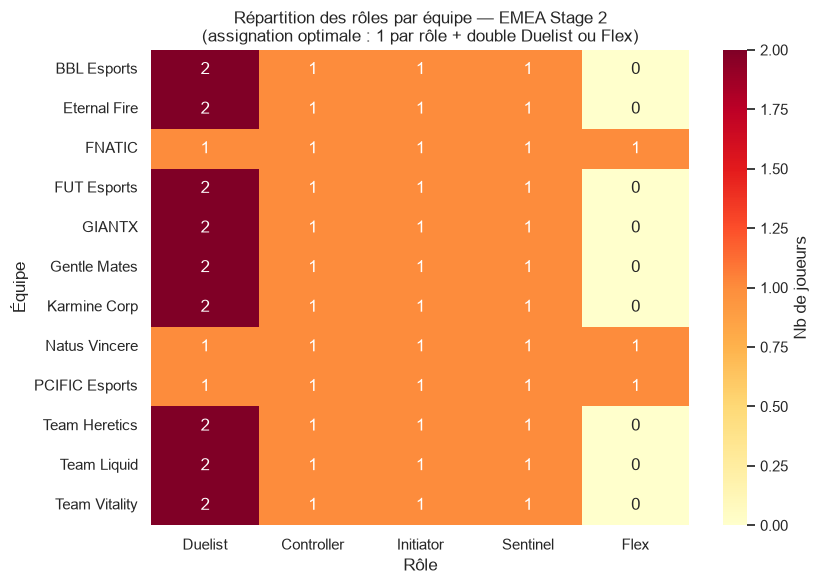

In [53]:
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.heatmap(role_counts, annot=True, fmt="d", cmap="YlOrRd", cbar_kws={"label": "Nb de joueurs"}, ax=ax)
ax.set_title("Répartition des rôles par équipe — EMEA Stage 2\n(assignation optimale : 1 par rôle + double Duelist ou Flex)")
ax.set_ylabel("Équipe")
ax.set_xlabel("Rôle")
plt.tight_layout()
capture_figure(fig, "heatmap_roles")
plt.show()


### Graphique "marché des transferts" — quadrants

Reprend le scatter individuel vs collectif, avec des quadrants explicites et les flèches des
meilleures spéculations de transfert compatibles (section 17) superposées.

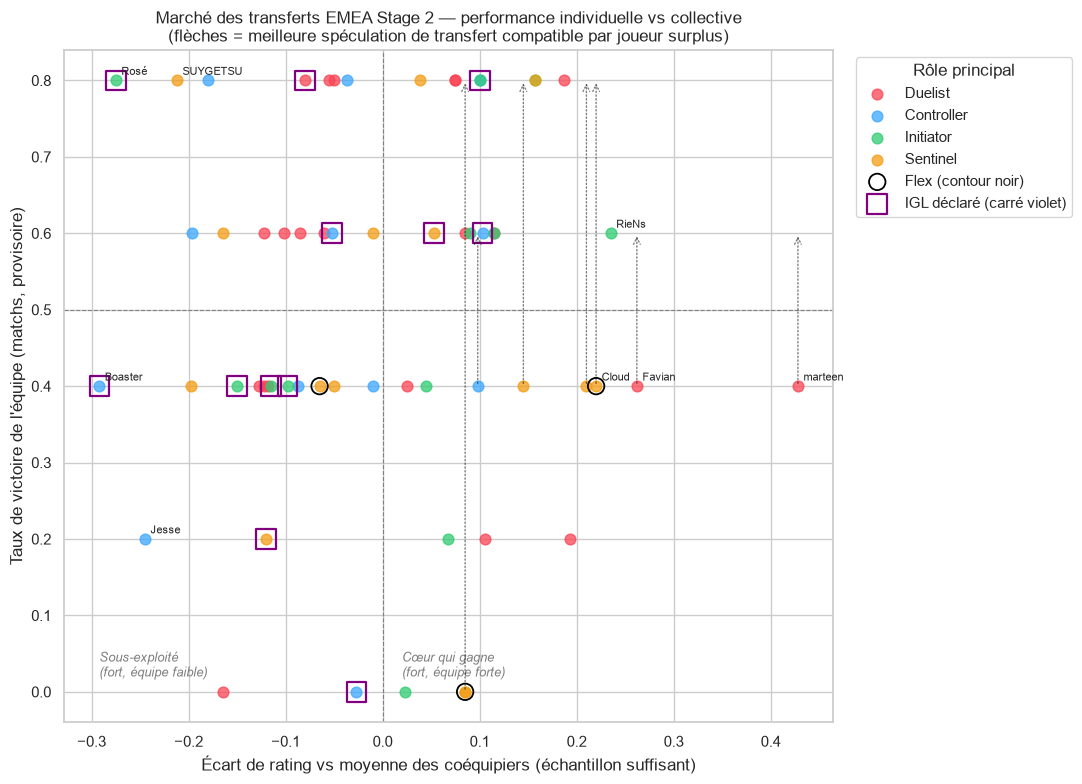

In [55]:
plot_df = df_clean[df_clean["sample_ok"]].dropna(subset=["rating_gap_vs_team", "match_win_rate", "role_final"])

roles_palette = {"Duelist": "#fa4454", "Controller": "#3ba7ff", "Initiator": "#2ecc71", "Sentinel": "#f39c12"}

fig, ax = plt.subplots(figsize=(11, 8))

for role, color in roles_palette.items():
    subset = plot_df[plot_df["role_final"] == role]
    ax.scatter(subset["rating_gap_vs_team"], subset["match_win_rate"], label=role, color=color, alpha=0.75, s=60)

flex_subset = plot_df[plot_df["is_flex"]]
ax.scatter(flex_subset["rating_gap_vs_team"], flex_subset["match_win_rate"],
           facecolors="none", edgecolors="black", s=140, linewidths=1.3, label="Flex (contour noir)")

igl_subset = plot_df[plot_df["is_igl"]]
ax.scatter(igl_subset["rating_gap_vs_team"], igl_subset["match_win_rate"],
           facecolors="none", edgecolors="purple", marker="s", s=200, linewidths=1.6, label="IGL déclaré (carré violet)")

ax.axhline(0.5, color="grey", linestyle="--", linewidth=0.8)
ax.axvline(0, color="grey", linestyle="--", linewidth=0.8)
quadrant_style = dict(fontsize=9, color="grey", style="italic")
ax.text(plot_df["rating_gap_vs_team"].min(), 0.02, "Sous-exploité\n(fort, équipe faible)", **quadrant_style)
ax.text(0.02, 0.02, "Cœur qui gagne\n(fort, équipe forte)", **quadrant_style)

extremes = pd.concat([plot_df.nlargest(4, "rating_gap_vs_team"), plot_df.nsmallest(4, "rating_gap_vs_team")])
for _, row in extremes.iterrows():
    ax.annotate(row["player"], (row["rating_gap_vs_team"], row["match_win_rate"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")

if not df_transfer_speculation.empty:
    best_per_player = df_transfer_speculation.sort_values("gain_potentiel", ascending=False).groupby("joueur_surplus").head(1)
    for _, row in best_per_player.iterrows():
        origin = plot_df[plot_df["player"] == row["joueur_surplus"]]
        target_team_rate = df_clean.loc[df_clean["team_full"] == row["equipe_cible"], "match_win_rate"]
        if origin.empty or target_team_rate.empty:
            continue
        x0, y0 = origin["rating_gap_vs_team"].values[0], origin["match_win_rate"].values[0]
        y1 = target_team_rate.values[0]
        ax.annotate("", xy=(x0, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="->", color="black", alpha=0.5, linestyle=":"))

ax.set_xlabel("Écart de rating vs moyenne des coéquipiers (échantillon suffisant)")
ax.set_ylabel("Taux de victoire de l'équipe (matchs, provisoire)")
ax.set_title("Marché des transferts EMEA Stage 2 — performance individuelle vs collective\n(flèches = meilleure spéculation de transfert compatible par joueur surplus)")
ax.legend(title="Rôle principal", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
capture_figure(fig, "scatter_marche_transferts")
plt.show()


C:\Users\emman\AppData\Local\Temp\ipykernel_10460\335489493.py:19: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\emman\AppData\Local\Temp\ipykernel_10460\335489493.py:19: UserWarning: Glyph 9889 (\N{HIGH VOLTAGE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\emman\AppData\Local\Temp\ipykernel_10460\528744894.py:10: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
C:\Users\emman\AppData\Local\Temp\ipykernel_10460\528744894.py:10: UserWarning: Glyph 9889 (\N{HIGH VOLTAGE SIGN}) missing from font(s) Arial.
  fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
C:\Users\emman\Downloads\projet_efrei_stage\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\emman\Downloads\projet_efrei_stage\.venv\Lib\sit

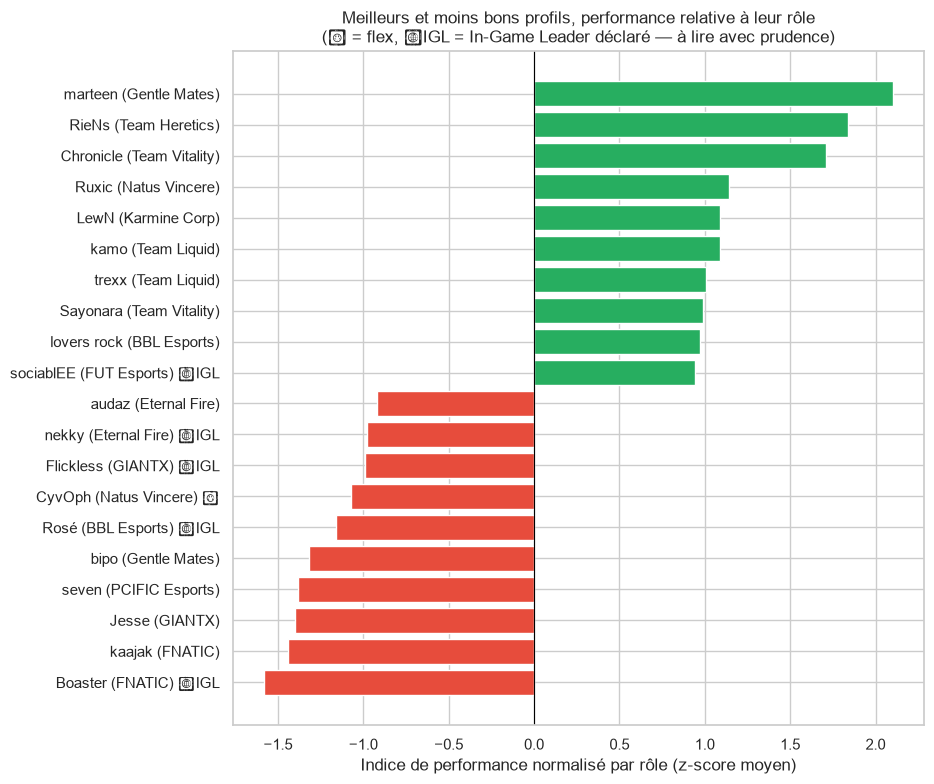

In [56]:
ranked = df_clean[df_clean["sample_ok"]].dropna(subset=["performance_index_role"])
top_bottom = pd.concat([
    ranked.nlargest(10, "performance_index_role")[["player", "team_full", "role_final", "performance_index_role", "is_flex", "is_igl"]],
    ranked.nsmallest(10, "performance_index_role")[["player", "team_full", "role_final", "performance_index_role", "is_flex", "is_igl"]],
])
top_bottom = top_bottom.sort_values("performance_index_role")
labels = (
    top_bottom["player"] + " (" + top_bottom["team_full"].fillna("?") + ")"
    + top_bottom["is_flex"].map({True: " ⚡", False: ""})
    + top_bottom["is_igl"].map({True: " 🎯IGL", False: ""})
)
colors = ["#e74c3c" if v < 0 else "#27ae60" for v in top_bottom["performance_index_role"]]

fig, ax = plt.subplots(figsize=(9.5, 8))
ax.barh(labels, top_bottom["performance_index_role"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Indice de performance normalisé par rôle (z-score moyen)")
ax.set_title("Meilleurs et moins bons profils, performance relative à leur rôle\n(⚡ = flex, 🎯IGL = In-Game Leader déclaré — à lire avec prudence)")
plt.tight_layout()
capture_figure(fig, "bar_top_bottom")
plt.show()


## 19. Export Excel — seul fichier produit par ce notebook

In [58]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M")
filename = output_dir / f"vlr_emea_stage2_roster_analysis_{timestamp}.xlsx"

df_export = df_clean.drop(columns=["agents", "role_distribution"]).copy()
df_export["agents_detail"] = df_clean["agents"].apply(
    lambda lst: "; ".join(f"{a} ({p}%)" for a, p in lst) if lst else ""
)
df_export["role_detail"] = df_clean["role_distribution"].apply(
    lambda d: "; ".join(f"{k}: {v}%" for k, v in d.items() if v > 0) if d else ""
)

with pd.ExcelWriter(filename, engine="openpyxl") as writer:
    df_export.to_excel(writer, sheet_name="Joueurs", index=False)
    team_strength.to_excel(writer, sheet_name="Résumé équipes", index=False)
    role_counts.reset_index().to_excel(writer, sheet_name="Rôles par équipe", index=False)
    nat_profile.reset_index().to_excel(writer, sheet_name="Composition nationale", index=False)
    df_team_synthesis.to_excel(writer, sheet_name="Synthèse équipes", index=False)
    df_transfer_speculation.to_excel(writer, sheet_name="Spéculations transferts", index=False)

    workbook = writer.book
    ws_charts = workbook.create_sheet("Graphiques")
    row_cursor = 1
    for name, img in chart_images.items():
        img.anchor = f"A{row_cursor}"
        ws_charts.add_image(img)
        row_cursor += 35

    for sheet_name in writer.sheets:
        if sheet_name == "Graphiques":
            continue
        ws = writer.sheets[sheet_name]
        for col_cells in ws.columns:
            length = max((len(str(c.value)) if c.value is not None else 0) for c in col_cells)
            col_letter = get_column_letter(col_cells[0].column)
            ws.column_dimensions[col_letter].width = min(length + 2, 45)
        ws.freeze_panes = "A2"

print(f"Fichier Excel généré : {filename.resolve()}")
print("(C'est le seul fichier produit par ce notebook — les graphiques sont uniquement à l'intérieur, feuille 'Graphiques'.)")


Fichier Excel généré : C:\Users\emman\Downloads\output\vlr_emea_stage2_roster_analysis_20260804_2354.xlsx
(C'est le seul fichier produit par ce notebook — les graphiques sont uniquement à l'intérieur, feuille 'Graphiques'.)


## 20. Téléchargement du fichier

In [60]:
try:
    from google.colab import files as colab_files  # type: ignore
    colab_files.download(str(filename))
    print("Téléchargement déclenché via Google Colab.")
except ImportError:
    import os
    import sys

    print("Environnement local détecté (pas Google Colab).")
    print(f"Fichier disponible ici : {filename.resolve()}")

    if sys.platform == "win32":
        try:
            os.startfile(filename.resolve())
        except Exception as e:
            print(f"Impossible d'ouvrir automatiquement le fichier: {e}")


Environnement local détecté (pas Google Colab).
Fichier disponible ici : C:\Users\emman\Downloads\output\vlr_emea_stage2_roster_analysis_20260804_2354.xlsx


## 21. Limites méthodologiques — à lire avant toute conclusion

- **L'assignation de rôle (section 10) repose sur une hypothèse forte, vérifiée sur ce dataset
  mais pas garantie universelle** : "chaque équipe aligne exactement 1 Duelist/1 Controller/
  1 Initiator/1 Sentinel, et le 5e joueur double le Duelist ou flex." Sur ces 12 équipes, 9
  doublent effectivement le Duelist et les 3 exceptions (FNATIC, Natus Vincere, PCIFIC Esports)
  convergent toutes vers un flex à dominante Sentinel — un pattern cohérent, mais qui pourrait ne
  pas se vérifier sur un autre événement ou une méta différente. Si `assign_team_roles` échoue à
  produire une affectation sensée sur un futur dataset, c'est le premier endroit à vérifier.
- **Échantillon limité** : un seul stage. Le filtre `MIN_MAPS = 5` retire les cas les plus
  extrêmes, mais reste un échantillon statistiquement bruyant pour 60 joueurs.
- **`match_win_rate` est provisoire** : l'événement est en cours au moment du scraping.
- **Le rôle de base (`main_role`) reste une estimation**, avec deux ajustements empiriques
  (Viper → Sentinel, Chamber en mixte 50/50) spécifiques à ce dataset — voir section 9bis avant
  réutilisation sur un autre event/patch.
- **`IGL_MAP` mélange deux niveaux de confiance** : 3 entrées sourcées officiellement, 9 fournies
  de mémoire — utiles mais pas vérifiées côté source primaire par ce notebook.
- **La section 17 (spéculations de transfert) reste la plus fragile.** Le filtre "roster fermé"
  (≥80% d'une nationalité) est un heuristique de bon sens, pas une règle du circuit. Aucune
  variable de contrat, budget, visa, âge, langue parlée, staff/coaching, ou volonté du joueur de
  bouger n'est dans ce dataset — ce sont pourtant les facteurs qui décident réellement d'un
  transfert. Cette section produit des **pistes de lecture statistiquement défendables**, pas des
  prédictions ni des recommandations de recrutement.
- **Ce notebook NE prédit PAS de transfert.** À confronter systématiquement à du contexte
  qualitatif (scène, interviews, connaissances de l'écosystème) avant toute conclusion.

---
# Partie 3 — Stage 1 → Stage 2 : les changements ont-ils payé ?

**Objectif** : comparer le roster et les performances de chaque équipe entre le Stage 1
(`event_id=2863`) et le Stage 2 (ce notebook), pour objectiver — à partir des données, pas de
l'impression générale — si un transfert, un changement de rôle, ou au contraire la stabilité,
a été suivi d'une progression ou d'une régression.

⚠️ **Ce que cette comparaison peut et ne peut pas dire** :
- Elle peut montrer une **corrélation temporelle** (le joueur/l'équipe va mieux ou moins bien après
  le changement).
- Elle ne peut PAS isoler la **cause** : une progression après un transfert peut venir du transfert,
  d'une meilleure préparation, d'un adversaire plus faible sur ce stage, ou du hasard d'échantillon.
  Deux stages, ce n'est pas assez pour trancher — c'est un indice, pas une preuve.
- Un changement de rôle ET d'équipe simultané (ex: Cloud) rend impossible de dire lequel des deux
  facteurs explique la variation observée.

## 22. Pipeline générique réutilisable pour n'importe quel stage

Plutôt que de dupliquer tout le code de scraping, on regroupe les étapes déjà définies plus haut
(`fetch_soup`, `parse_player_cell`, `parse_agent_cell`, `compute_role_distribution`,
`assign_team_roles`, etc.) dans une seule fonction `scrape_and_build_stage`, appelable pour
n'importe quel event VLR.gg.

In [ ]:
def scrape_and_build_stage(event_id, event_slug, min_maps=MIN_MAPS):
    """Reproduit tout le pipeline (scraping -> nettoyage -> rôles -> assignation -> force
    d'équipe) pour un event VLR.gg donné, et retourne un df_clean prêt à l'emploi."""

    stats_url = f"{BASE_URL}/event/stats/{event_id}/{event_slug}"
    soup_local = fetch_soup(stats_url)

    table_local = soup_local.select_one("table.wf-table-inset.mod-overview") or soup_local.find("table")
    assert table_local is not None, f"Table introuvable pour {stats_url}"
    tbody_rows_local = table_local.select("tbody tr")

    rows_data_local = []
    for tr in tbody_rows_local:
        tds = tr.find_all("td")
        if len(tds) < EXPECTED_TD_COUNT:
            continue
        player_name, team, player_link, country_code = parse_player_cell(tds[0])
        agents = parse_agent_cell(tds[1])
        stat_texts = [td.get_text(strip=True) for td in tds[2:23]]
        kmax_val, kmax_link = parse_kmax_cell(tds[KMAX_TD_INDEX])
        row = dict(zip(STAT_COLUMNS, stat_texts))
        row.update({"player": player_name, "team": team, "player_link": player_link,
                     "country_code": country_code, "agents": agents, "kmax_link": kmax_link})
        rows_data_local.append(row)

    df_raw_local = pd.DataFrame(rows_data_local)

    df_local = pd.DataFrame()
    df_local["player"] = df_raw_local["player"]
    df_local["team"] = df_raw_local["team"]
    df_local["country_code"] = df_raw_local["country_code"]
    df_local["nationality"] = df_local["country_code"].apply(decode_country)
    df_local["maps"] = df_raw_local["maps"].apply(to_int)
    df_local["rounds"] = df_raw_local["rnd"].apply(to_int)
    df_local["rating"] = df_raw_local["rating"].apply(to_float)
    df_local["acs"] = df_raw_local["acs"].apply(to_float)
    df_local["kd_ratio"] = df_raw_local["kd"].apply(to_float)
    df_local["kast_pct"] = df_raw_local["kast"].apply(to_float)
    df_local["adr"] = df_raw_local["adr"].apply(to_float)
    df_local["kpr"] = df_raw_local["kpr"].apply(to_float)
    df_local["agents"] = df_raw_local["agents"]

    df_local["role_distribution"] = df_local["agents"].apply(compute_role_distribution)
    df_local["main_role"] = df_local["role_distribution"].apply(
        lambda d: max(d, key=d.get) if d and max(d.values()) > 0 else None
    )
    df_local["sample_ok"] = df_local["maps"] >= min_maps
    df_local["team_full"] = df_local["team"].map(TEAM_ABBR_MAP)

    df_local = assign_team_roles(df_local)
    df_local["is_flex"] = df_local["team_slot"] == "Flex"

    # Force d'équipe (résultats de matchs) pour ce stage
    matches_soup_local = fetch_matches_html(event_id, event_slug)
    match_anchors_local = matches_soup_local.select("a.match-item")
    if not match_anchors_local:
        match_anchors_local = [a for a in matches_soup_local.find_all("a", href=True) if re.search(r"^/\d+/", a["href"])]
    matches_parsed_local = [parse_match_anchor(a) for a in match_anchors_local]
    df_matches_local = pd.DataFrame(matches_parsed_local)
    completed_local = df_matches_local[
        (df_matches_local["status"] == "Completed") & df_matches_local["team1"].notna() & df_matches_local["team2"].notna()
    ]
    rows_ts = []
    for _, m in completed_local.iterrows():
        t1, t2, s1, s2 = m["team1"], m["team2"], m["score1"], m["score2"]
        rows_ts.append({"team_full": t1, "match_win": int(s1 > s2)})
        rows_ts.append({"team_full": t2, "match_win": int(s2 > s1)})
    df_ts_local = pd.DataFrame(rows_ts)
    team_strength_local = (
        df_ts_local.groupby("team_full")["match_win"].agg(["count", "sum"]).reset_index()
        .rename(columns={"count": "matches_played", "sum": "matches_won"})
    )
    team_strength_local["match_win_rate"] = (team_strength_local["matches_won"] / team_strength_local["matches_played"]).round(3)

    df_local = df_local.merge(team_strength_local[["team_full", "match_win_rate"]], on="team_full", how="left")

    print(f"{event_slug} : {len(df_local)} joueurs, {df_local['sample_ok'].sum()} à échantillon suffisant, "
          f"{team_strength_local['team_full'].nunique()} équipes avec résultats de matchs.")

    return df_local


STAGE1_EVENT_ID = 2863
STAGE1_EVENT_SLUG = "vct-2026-emea-stage-1"

df_stage1 = scrape_and_build_stage(STAGE1_EVENT_ID, STAGE1_EVENT_SLUG)
df_stage2 = df_clean.copy()  # déjà construit dans les parties 1 et 2 de ce notebook

df_stage1[["player", "team_full", "main_role", "role_final", "rating", "match_win_rate"]].head(10)


## 23. Trajectoires individuelles Stage 1 → Stage 2

Fusion sur le nom de joueur. Trois cas : présent aux deux stages (avec ou sans changement
d'équipe / de rôle), arrivé en EMEA seulement au Stage 2, ou parti après le Stage 1.

In [ ]:
traj = df_stage1[["player", "team_full", "main_role", "role_final", "rating", "match_win_rate"]].rename(
    columns={"team_full": "team_s1", "main_role": "main_role_s1", "role_final": "role_s1",
             "rating": "rating_s1", "match_win_rate": "win_rate_s1"}
).merge(
    df_stage2[["player", "team_full", "main_role", "role_final", "rating", "match_win_rate"]].rename(
        columns={"team_full": "team_s2", "main_role": "main_role_s2", "role_final": "role_s2",
                 "rating": "rating_s2", "match_win_rate": "win_rate_s2"}
    ),
    on="player", how="outer", indicator=True
)

traj["statut"] = traj["_merge"].map({
    "both": "Présent aux deux stages",
    "left_only": "Parti après le Stage 1",
    "right_only": "Arrivé au Stage 2",
})
traj["equipe_changee"] = (traj["team_s1"] != traj["team_s2"]) & traj["team_s1"].notna() & traj["team_s2"].notna()
traj["role_change"] = (traj["role_s1"] != traj["role_s2"]) & traj["role_s1"].notna() & traj["role_s2"].notna()
traj["delta_rating"] = (traj["rating_s2"] - traj["rating_s1"]).round(3)
traj = traj.drop(columns=["_merge"])

print(traj["statut"].value_counts())
print(f"\nDont changements d'équipe (EMEA -> EMEA) : {traj['equipe_changee'].sum()}")
print(f"Dont changements de rôle principal (à équipe et joueur présents aux 2 stages) : {traj['role_change'].sum()}")

traj.sort_values("delta_rating", ascending=False)


### 23bis. Les plus grosses progressions et régressions (joueurs présents aux deux stages)

In [ ]:
both_stages = traj[traj["statut"] == "Présent aux deux stages"].dropna(subset=["delta_rating"])

print("=== Top 10 progressions ===")
print(both_stages.nlargest(10, "delta_rating")[
    ["player", "team_s1", "team_s2", "role_s1", "role_s2", "rating_s1", "rating_s2", "delta_rating"]
].to_string(index=False))

print("\n=== Top 10 régressions ===")
print(both_stages.nsmallest(10, "delta_rating")[
    ["player", "team_s1", "team_s2", "role_s1", "role_s2", "rating_s1", "rating_s2", "delta_rating"]
].to_string(index=False))


## 24. Bilan des changements de roster, par équipe

Pour chaque équipe du Stage 2, on liste qui est parti (y compris vers une autre équipe EMEA) et
qui est arrivé (y compris depuis une autre équipe EMEA), avec leur niveau de rating au moment du
départ / de l'arrivée, puis un **verdict généré automatiquement** à partir de deux signaux :
1. Le niveau moyen des arrivants vs celui des partants (upgrade individuel ou non)
2. L'évolution du taux de victoire de l'équipe entre les deux stages

In [ ]:
def team_roster_changes(team, traj):
    left_pure = traj[(traj["statut"] == "Parti après le Stage 1") & (traj["team_s1"] == team)]
    left_transfer = traj[(traj["statut"] == "Présent aux deux stages") & (traj["team_s1"] == team) & traj["equipe_changee"]]
    departs = pd.concat([left_pure[["player", "rating_s1"]], left_transfer[["player", "rating_s1"]]])

    right_pure = traj[(traj["statut"] == "Arrivé au Stage 2") & (traj["team_s2"] == team)]
    right_transfer = traj[(traj["statut"] == "Présent aux deux stages") & (traj["team_s2"] == team) & traj["equipe_changee"]]
    arrivees = pd.concat([right_pure[["player", "rating_s2"]], right_transfer[["player", "rating_s2"]]])

    return departs, arrivees


def build_verdict(team, departs, arrivees, win_rate_s1, win_rate_s2):
    delta_wr = None
    if pd.notna(win_rate_s1) and pd.notna(win_rate_s2):
        delta_wr = round(win_rate_s2 - win_rate_s1, 2)

    if len(departs) == 0 and len(arrivees) == 0:
        if delta_wr is None:
            return "Roster stable, pas de comparaison de résultats possible."
        if delta_wr > 0.05:
            return f"Roster inchangé, taux de victoire en hausse ({delta_wr:+.0%}) : la stabilité/le temps de jeu ensemble a payé."
        elif delta_wr < -0.05:
            return f"Roster inchangé, taux de victoire en baisse ({delta_wr:+.0%}) : érosion malgré la continuité."
        else:
            return "Roster inchangé, taux de victoire stable."

    avg_depart = departs["rating_s1"].mean() if len(departs) else None
    avg_arrivee = arrivees["rating_s2"].mean() if len(arrivees) else None

    if avg_depart is not None and avg_arrivee is not None:
        upgrade = avg_arrivee - avg_depart
        niveau = f"niveau moyen arrivants {avg_arrivee:.2f} vs partants {avg_depart:.2f} ({upgrade:+.2f})"
    else:
        niveau = "comparaison de niveau incomplète (arrivée hors EMEA au Stage 1 ou l'inverse)"

    if delta_wr is None:
        return f"Changements de roster ({niveau}), résultats d'équipe non comparables."

    upgrade_ok = (avg_depart is None or avg_arrivee is None or upgrade >= 0)

    if delta_wr > 0.05 and upgrade_ok:
        return f"Pari réussi : {niveau}, et le taux de victoire progresse ({delta_wr:+.0%})."
    if delta_wr > 0.05 and not upgrade_ok:
        return (f"Taux de victoire en hausse ({delta_wr:+.0%}) malgré un niveau moyen des arrivants "
                f"inférieur à celui des partants ({niveau}) — d'autres facteurs (système de jeu, "
                f"coaching, calendrier) expliquent probablement la progression, pas le recrutement seul.")
    if avg_depart is not None and avg_arrivee is not None and upgrade > 0:
        return f"Upgrade individuel confirmé ({niveau}) mais pas encore traduit collectivement (Δ win rate {delta_wr:+.0%}) — cf. FNATIC/Cloud."
    if delta_wr < -0.05:
        return f"Pari perdant à ce stade : {niveau}, taux de victoire en baisse ({delta_wr:+.0%})."
    return f"Effet mitigé : {niveau}, taux de victoire stable ({delta_wr:+.0%})."


rows = []
win_rates_s1 = df_stage1.drop_duplicates("team_full").set_index("team_full")["match_win_rate"]
win_rates_s2 = df_stage2.drop_duplicates("team_full").set_index("team_full")["match_win_rate"]

for team in sorted(df_stage2["team_full"].dropna().unique()):
    departs, arrivees = team_roster_changes(team, traj)
    wr_s1 = win_rates_s1.get(team)
    wr_s2 = win_rates_s2.get(team)
    verdict = build_verdict(team, departs, arrivees, wr_s1, wr_s2)
    rows.append({
        "team": team,
        "win_rate_s1": wr_s1,
        "win_rate_s2": wr_s2,
        "delta_win_rate": round(wr_s2 - wr_s1, 3) if pd.notna(wr_s1) and pd.notna(wr_s2) else None,
        "departs": "; ".join(f"{r.player} ({r.rating_s1:.2f})" for r in departs.itertuples()) or "Aucun",
        "arrivees": "; ".join(f"{r.player} ({r.rating_s2:.2f})" for r in arrivees.itertuples()) or "Aucune",
        "verdict": verdict,
    })

df_bilan_roster = pd.DataFrame(rows).sort_values("delta_win_rate", ascending=False)
df_bilan_roster


## 25. Score composite — indice de besoin de changement par équipe

Combine trois signaux du Stage 2 en un seul indice (plus il est élevé, plus la situation de
l'équipe justifie statistiquement un changement) :
1. **Résultat** : taux de victoire (inversé — moins on gagne, plus l'indice monte)
2. **Maillon faible** : indice de performance du pire joueur de l'équipe (déjà normalisé par rôle)
3. **Dynamique** : delta moyen de rating des joueurs présents aux deux stages (momentum
   négatif = équipe qui se dégrade malgré tout)

In [ ]:
team_health_rows = []

for team in sorted(df_stage2["team_full"].dropna().unique()):
    team_df_s2 = df_stage2[(df_stage2["team_full"] == team) & (df_stage2["sample_ok"])]
    win_rate = team_df_s2["match_win_rate"].iloc[0] if not team_df_s2.empty else np.nan
    weakest = team_df_s2["performance_index_role"].min() if not team_df_s2.empty else np.nan

    momentum_pool = both_stages[both_stages["team_s2"] == team]["delta_rating"]
    momentum = momentum_pool.mean() if len(momentum_pool) else np.nan

    team_health_rows.append({
        "team": team, "win_rate_s2": win_rate, "pire_joueur_z": weakest, "momentum_moyen": momentum,
    })

df_health = pd.DataFrame(team_health_rows)

def z(s):
    return (s - s.mean()) / s.std(ddof=0) if s.std(ddof=0) > 0 else s * 0

df_health["win_rate_z"] = z(df_health["win_rate_s2"])
df_health["pire_joueur_z_norm"] = z(df_health["pire_joueur_z"])
df_health["momentum_z"] = z(df_health["momentum_moyen"].fillna(df_health["momentum_moyen"].mean()))

# Indice de besoin de changement : on inverse les 3 composantes (plus bas = plus urgent -> indice plus haut)
df_health["indice_besoin_changement"] = (
    -df_health["win_rate_z"] - df_health["pire_joueur_z_norm"] - df_health["momentum_z"]
).round(2)

df_health = df_health.sort_values("indice_besoin_changement", ascending=False)
df_health[["team", "win_rate_s2", "pire_joueur_z", "momentum_moyen", "indice_besoin_changement"]]


## 26. Export Excel — ajout des feuilles Stage 1 → Stage 2

On rouvre le fichier déjà généré (section 19) et on y ajoute trois feuilles, sans dupliquer les
feuilles déjà écrites.

In [ ]:
with pd.ExcelWriter(filename, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    traj.to_excel(writer, sheet_name="Trajectoires S1-S2", index=False)
    df_bilan_roster.to_excel(writer, sheet_name="Bilan transferts S1-S2", index=False)
    df_health.to_excel(writer, sheet_name="Score composite équipes", index=False)

    for sheet_name in ["Trajectoires S1-S2", "Bilan transferts S1-S2", "Score composite équipes"]:
        ws = writer.sheets[sheet_name]
        for col_cells in ws.columns:
            length = max((len(str(c.value)) if c.value is not None else 0) for c in col_cells)
            col_letter = get_column_letter(col_cells[0].column)
            ws.column_dimensions[col_letter].width = min(length + 2, 60)
        ws.freeze_panes = "A2"

print(f"3 feuilles ajoutées à {filename.resolve()} : 'Trajectoires S1-S2', 'Bilan transferts S1-S2', 'Score composite équipes'.")


## 27. Limites spécifiques à cette comparaison Stage 1 → Stage 2

- **Deux points de mesure, ce n'est pas une série temporelle.** Une progression ou régression peut
  venir d'un adversaire plus faible/fort sur ce stage précis, pas uniquement du changement observé.
- **Les rôles Stage 1 sont recalculés avec le mapping actuel** (Viper → Sentinel, Chamber mixte) —
  cohérent avec le Stage 2, mais pas revérifié spécifiquement sur l'échantillon Stage 1 (la
  section 10bis n'a été relancée que sur les données Stage 2).
- **Un changement de rôle ET d'équipe simultané est confondu** : impossible de séparer l'effet du
  nouveau rôle de celui du nouvel environnement (cf. Cloud : GIANTX/Initiator → FNATIC/Sentinel).
- **`indice_besoin_changement` reste un indicateur composite arbitraire** (pondération égale des
  3 signaux) — à ajuster selon ce qu'on veut prioriser (résultat immédiat vs dynamique de fond).

---
# Partie 4 — Kickoff, pool Challengers, et matching de recrutement

Trois ajouts :
1. **Kickoff** (`event_id=2684`) comme 3e point de mesure, pour de vraies tendances (pas juste
   un avant/après)
2. **Pool Challengers EMEA** (VCL) comme vivier de recrutement potentiel — deux events couvrent
   toute l'EMEA en un seul point d'entrée chacun : `Stage 3` (id 3016, 16 équipes venues des
   ligues nationales DACH/France/MENA/NORTH-EAST/Espagne/Türkiye) et la `Last Chance Qualifier`
   (id 3018).
3. **Score d'adéquation de rôle** + **matching "qui pourrait compléter ce roster"**, combinant
   VCT (rivaux) et VCL (vivier).

⚠️ **Sur la comparaison VCT ↔ VCL** : le niveau de jeu diffère structurellement entre les deux
circuits (la VCL est le niveau développement). Un rating VCL brut n'est PAS directement comparable
à un rating VCT — on ne s'en sert que pour **repérer des profils intéressants à surveiller**, pas
pour affirmer qu'un joueur VCL "vaut" tel joueur VCT.

## 28. Kickoff comme 3e point de mesure

In [ ]:
KICKOFF_EVENT_ID = 2684
KICKOFF_EVENT_SLUG = "vct-2026-emea-kickoff"

df_kickoff = scrape_and_build_stage(KICKOFF_EVENT_ID, KICKOFF_EVENT_SLUG)
df_kickoff[["player", "team_full", "main_role", "rating", "match_win_rate"]].head(10)


In [ ]:
def build_long_history(stage_dfs):
    """stage_dfs: liste de tuples (nom_stage, df, ordre) -> un DataFrame long pour tracer des tendances."""
    frames = []
    for name, df, order in stage_dfs:
        tmp = df[["player", "team_full", "main_role", "rating", "match_win_rate"]].copy()
        tmp["stage"] = name
        tmp["stage_order"] = order
        frames.append(tmp)
    return pd.concat(frames, ignore_index=True)


df_history = build_long_history([
    ("Kickoff", df_kickoff, 1),
    ("Stage 1", df_stage1, 2),
    ("Stage 2", df_stage2, 3),
])

# Nombre de stages joués par joueur -> repère les habitués vs les passages éclairs
presence = df_history.groupby("player")["stage"].nunique().sort_values(ascending=False)
print("Joueurs présents sur les 3 stages :", (presence == 3).sum())
print("Joueurs présents sur 1 seul stage (rotation/relégation/recrue récente) :", (presence == 1).sum())

df_history.head(10)


### 28bis. Équipes en tendance — momentum sur 3 points

Régression linéaire simple (pente du rating moyen d'équipe) sur les 3 stages, pour distinguer une
équipe en progression continue d'une équipe qui n'a fait qu'un pic ponctuel.

In [ ]:
team_trend_rows = []
for team, g in df_history.dropna(subset=["team_full"]).groupby("team_full"):
    by_stage = g.groupby("stage_order")["rating"].mean()
    if len(by_stage) < 2:
        continue
    x = by_stage.index.values.astype(float)
    y = by_stage.values
    slope = np.polyfit(x, y, 1)[0]
    team_trend_rows.append({
        "team": team,
        "rating_moyen_kickoff": by_stage.get(1, np.nan),
        "rating_moyen_s1": by_stage.get(2, np.nan),
        "rating_moyen_s2": by_stage.get(3, np.nan),
        "pente_tendance": round(slope, 3),
    })

df_team_trend = pd.DataFrame(team_trend_rows).sort_values("pente_tendance", ascending=False)
df_team_trend


## 29. Pool Challengers EMEA (vivier de recrutement potentiel)

In [ ]:
CHALLENGERS_EVENTS = [
    (3016, "challengers-2026-emea-stage-3"),
    (3018, "challengers-2026-emea-last-chance-qualifier"),
]

vcl_frames = []
for event_id, event_slug in CHALLENGERS_EVENTS:
    try:
        df_vcl_part = scrape_and_build_stage(event_id, event_slug, min_maps=3)
        df_vcl_part["source_event"] = event_slug
        vcl_frames.append(df_vcl_part)
    except Exception as e:
        print(f"⚠️ Échec sur {event_slug} : {e}")

df_vcl = pd.concat(vcl_frames, ignore_index=True) if vcl_frames else pd.DataFrame()

if not df_vcl.empty:
    # Un joueur peut apparaître dans les deux events (Stage 3 + LCQ) -> on garde sa meilleure série (le plus de maps)
    df_vcl = df_vcl.sort_values("maps", ascending=False).drop_duplicates("player", keep="first")
    print(f"{len(df_vcl)} joueurs VCL distincts récupérés (Stage 3 + LCQ), {df_vcl['sample_ok'].sum()} à échantillon suffisant.")

df_vcl[["player", "team_full", "main_role", "rating", "maps"]].sort_values("rating", ascending=False).head(15)


### 29bis. Repères de niveau VCT vs VCL (pour calibrer, pas pour comparer brut à brut)

Comparer les distributions de rating par rôle entre les deux circuits — utile pour savoir de
combien "rabattre" un rating VCL avant de le comparer mentalement à un rating VCT.

In [ ]:
if not df_vcl.empty:
    comparison_rows = []
    for role in ROLES:
        vct_ratings = df_stage2.loc[(df_stage2["role_final"] == role) & (df_stage2["sample_ok"]), "rating"]
        vcl_ratings = df_vcl.loc[(df_vcl["main_role"] == role) & (df_vcl["sample_ok"]), "rating"]
        comparison_rows.append({
            "role": role,
            "rating_moyen_VCT": round(vct_ratings.mean(), 3) if len(vct_ratings) else np.nan,
            "rating_moyen_VCL": round(vcl_ratings.mean(), 3) if len(vcl_ratings) else np.nan,
            "ecart_VCT_moins_VCL": round(vct_ratings.mean() - vcl_ratings.mean(), 3) if len(vct_ratings) and len(vcl_ratings) else np.nan,
        })
    df_level_gap = pd.DataFrame(comparison_rows)
    print(df_level_gap.to_string(index=False))
else:
    print("Pool VCL vide — rien à comparer.")


## 30. Score d'adéquation de rôle

Un joueur peut être statistiquement bon dans l'absolu tout en étant **mal casté** : par exemple
un profil à faible `role_confidence` (il jongle entre agents de rôles différents sans dominante
claire) combiné à un `performance_index_role` négatif. Croiser les deux distingue 4 profils.

In [ ]:
def classify_role_fit(row):
    if pd.isna(row["role_confidence"]) or pd.isna(row["performance_index_role"]):
        return "Données insuffisantes"
    high_confidence = row["role_confidence"] >= 60
    good_perf = row["performance_index_role"] >= 0
    if high_confidence and good_perf:
        return "Bien casté"
    if high_confidence and not good_perf:
        return "Spécialiste sous-performant"
    if not high_confidence and good_perf:
        return "Flex qui marche"
    return "Profil flou à surveiller"


df_stage2["role_fit"] = df_stage2.apply(classify_role_fit, axis=1)
print(df_stage2[df_stage2["sample_ok"]]["role_fit"].value_counts())
df_stage2[df_stage2["sample_ok"]][["player", "team_full", "role_final", "role_confidence", "performance_index_role", "role_fit"]].sort_values("role_fit")


## 31. Matching — qui pourrait compléter ce roster ?

Pour une équipe et un rôle donnés, cherche les meilleurs candidats parmi :
- les joueurs des **autres équipes VCT** (rivaux, benchmark de niveau confirmé)
- le **vivier VCL** (Stage 3 + LCQ), avec le rating recalibré par l'écart de niveau moyen mesuré
  en 29bis, pour rester comparable

Filtré par compatibilité de roster (même logique "roster fermé" que la section 17).

In [ ]:
def find_best_fit_candidates(team, role, df_stage2, df_vcl, nat_profile, df_level_gap, n=5):
    profile = nat_profile.loc[team] if team in nat_profile.index else None
    team_nat = profile["nationalite_dominante"] if profile is not None and profile["roster_ferme"] else None

    # --- candidats VCT (rivaux) ---
    vct_pool = df_stage2[
        (df_stage2["role_final"] == role) & (df_stage2["sample_ok"]) & (df_stage2["team_full"] != team)
    ].copy()
    vct_pool["source"] = "VCT (rival)"
    vct_pool["rating_recalibre"] = vct_pool["rating"]
    vct_pool["score"] = vct_pool["performance_index_role"]

    # --- candidats VCL (vivier), rating recalibré par l'écart de niveau mesuré ---
    gap = df_level_gap.set_index("role")["ecart_VCT_moins_VCL"].get(role, 0) if not df_vcl.empty else 0
    vcl_pool = df_vcl[(df_vcl["main_role"] == role) & (df_vcl["sample_ok"])].copy() if not df_vcl.empty else pd.DataFrame()
    if not vcl_pool.empty:
        vcl_pool["source"] = "VCL (vivier)"
        vcl_pool["rating_recalibre"] = (vcl_pool["rating"] + gap).round(3)
        # Score approximatif : écart à la moyenne VCT du rôle, en unités de std VCT
        vct_role_stats = df_stage2.loc[(df_stage2["role_final"] == role) & (df_stage2["sample_ok"]), "rating"]
        std_vct = vct_role_stats.std(ddof=0) or 1
        mean_vct = vct_role_stats.mean()
        vcl_pool["score"] = ((vcl_pool["rating_recalibre"] - mean_vct) / std_vct).round(2)

    pool = pd.concat([
        vct_pool[["player", "team_full", "nationality", "source", "rating", "rating_recalibre", "score"]],
        vcl_pool[["player", "team_full", "nationality", "source", "rating", "rating_recalibre", "score"]] if not vcl_pool.empty else pd.DataFrame(),
    ], ignore_index=True)

    if team_nat is not None:
        pool["compatible_roster"] = pool["nationality"] == team_nat
    else:
        pool["compatible_roster"] = True

    pool = pool[pool["compatible_roster"]].sort_values("score", ascending=False)
    return pool.head(n)


# Exemple d'utilisation : qui pourrait renforcer le Controller de PCIFIC Esports (le plus faible du Stage 2) ?
example = find_best_fit_candidates("PCIFIC Esports", "Controller", df_stage2, df_vcl, nat_profile, df_level_gap if "df_level_gap" in dir() else pd.DataFrame(columns=["role","ecart_VCT_moins_VCL"]))
example


### 31bis. Limites du matching

- Le "recalibrage" VCL → VCT (section 29bis) est une moyenne globale par rôle, pas un ajustement
  individuel — un joueur VCL exceptionnel peut être sous-estimé, un joueur qui a fait un stage
  facile peut être surestimé.
- Aucune donnée de contrat, de coût de transfert, de visa/éligibilité région, ni de disponibilité
  réelle du joueur n'est prise en compte — ce sont pourtant des conditions bloquantes en pratique.
- Le filtre "roster fermé" reste un heuristique de bon sens, pas une règle du circuit.

## 32. Export Excel — feuilles Kickoff / VCL / matching

In [ ]:
with pd.ExcelWriter(filename, engine="openpyxl", mode="a", if_sheet_exists="replace") as writer:
    df_history.to_excel(writer, sheet_name="Historique 3 stages", index=False)
    df_team_trend.to_excel(writer, sheet_name="Tendance équipes", index=False)
    if not df_vcl.empty:
        df_vcl.drop(columns=["agents", "role_distribution"], errors="ignore").to_excel(
            writer, sheet_name="Pool Challengers VCL", index=False
        )
    df_stage2[df_stage2["sample_ok"]][
        ["player", "team_full", "role_final", "role_confidence", "performance_index_role", "role_fit"]
    ].to_excel(writer, sheet_name="Adequation role", index=False)

    for sheet_name in ["Historique 3 stages", "Tendance équipes", "Pool Challengers VCL", "Adequation role"]:
        if sheet_name not in writer.sheets:
            continue
        ws = writer.sheets[sheet_name]
        for col_cells in ws.columns:
            length = max((len(str(c.value)) if c.value is not None else 0) for c in col_cells)
            col_letter = get_column_letter(col_cells[0].column)
            ws.column_dimensions[col_letter].width = min(length + 2, 50)
        ws.freeze_panes = "A2"

print(f"Feuilles Kickoff / VCL / adéquation de rôle ajoutées à {filename.resolve()}")
